In [1]:
# Imports
import math
import numpy as np
import matplotlib.pyplot as plt
import numba as nb
import scipy.stats as sp
from numba import guvectorize
from dspeed.utils import numba_defaults_kwargs as nb_kwargs

# LEGEND specific imports
from lgdo import lh5, VectorOfVectors, WaveformTable, Table, ArrayOfEqualSizedArrays, Array
from lgdo.lh5 import LH5Store
from dspeed import build_dsp
from dspeed.vis import WaveformBrowser

# MISC
import matplotlib.pyplot as plt
import numpy as np
import awkward as ak
import glob

In [2]:
from dspeed.processors import optimize_nnls as nnls
from dspeed.processors import inject_gumbel
#from pygama.pargen.dsp_optimize import run_one_dsp

In [3]:
# we'll just use basic white noise as the basis of our waveforms, this is slightly different to the 
# waveform data we have where the lower frequencies are higher
mean = 0
std = 20
num_samples = 1000 # number of waveforms
wf_len = 32 #the number of points in the wavefunction
upsample=5
out_len = wf_len*upsample

samples = np.random.normal(mean, std, size=(num_samples, out_len))
#this create white noise


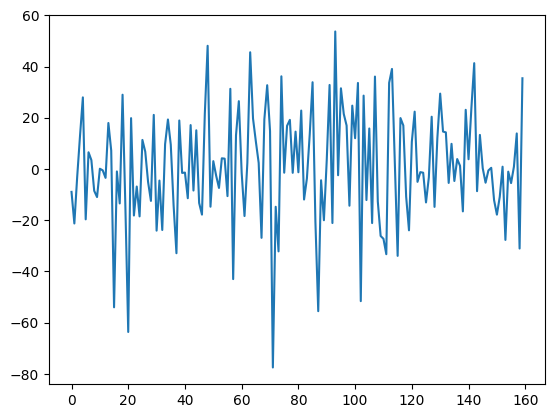

In [4]:
plt.figure()
plt.plot(samples[0,:])
plt.show()

In [5]:
# initialise the output object
full_wfs = np.zeros_like(samples)

In [6]:
# fix amplitude and width, vary t0 using uniform distribution
amplitude = 10000 #the bigger the amplitude, the clearer the peak. a small amplitude (>500) leads to an unclear peak. 
width = 2 * upsample / 5 #the smaller the width, the clearer the peak. a big width (>1.5) leads to an unclear peak.
t0_start = 11* upsample
shift = 5*upsample
full_t0s = np.random.uniform(t0_start,t0_start+shift,num_samples) #this indicates where the gumbel peak starts
t0s = full_t0s/upsample

In [810]:
test = np.zeros(out_len)
out = np.zeros(out_len)
out2 = np.zeros(out_len)
inject_gumbel(out, 10, 10, 2.5, out) 
inject_gumbel(out, 10, 14, 2.5, out) 
inject_gumbel(out2, 20, 12, 2.5, out2) 

array([0., 0., 0., ..., 0., 0., 0.])

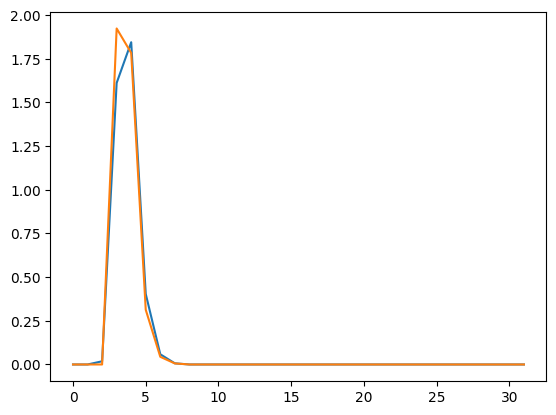

In [811]:
plt.figure()
plt.plot(out[np.arange(0,out_len,5)])
plt.plot(out2[np.arange(0,out_len,5)])
plt.show()

In [7]:
for i in range(num_samples):
    inject_gumbel(samples[i,:], amplitude, full_t0s[i], width, full_wfs[i,:]) 

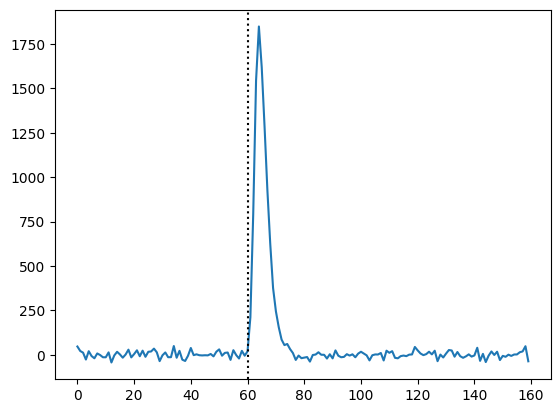

In [8]:
plt.figure()
plt.plot(full_wfs[100,:])
plt.axvline(full_t0s[100], color="black", ls=":")
plt.show()

In [9]:
wfs = full_wfs[:,np.arange(0,out_len, upsample)]

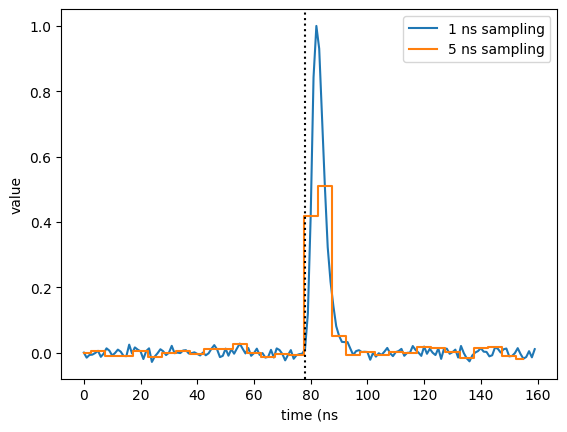

In [1342]:
plt.figure()
n_wf = 2
plt.plot(full_wfs[n_wf,:]/np.amax(full_wfs[n_wf,:]), label="1 ns sampling")
plt.step(np.arange(0,wf_len)*upsample , wfs[n_wf,:]/np.amax(full_wfs[n_wf,:]), where="mid", label="5 ns sampling")
plt.axvline(full_t0s[n_wf], color="black", ls=":")
plt.xlabel("time (ns")
plt.ylabel("value")
plt.legend()
plt.show()

In [11]:
def build_template_waveform(wfs_in, ts, upsample_factor=5):
    # Initialize extended arrays
    wf_len = len(wfs_in[0])
    wf_extended = np.zeros(wf_len * upsample_factor)
    counts = np.zeros(wf_len * upsample_factor)
    base = np.arange(wf_len)
    
    t0_shift = int(wf_len/4)
    shifts_list = np.floor((ts-t0_shift)*upsample_factor).astype(int)

    shifts = shifts_list[:, None]  # Shape (num_waveforms, 1) for broadcasting
    indices = base * upsample_factor - shifts  # Shape (num_waveforms, wf_len)
    
    # Scatter-add values to wf_extended and counts
    for i in range(num_samples):
        if indices[i][-1] > len(wf_extended):
            continue
        else:
            wf_extended[indices[i]] += wfs_in[i,:]
            counts[indices[i]] += np.ones(wf_len)
    
    start = int(t0_shift * upsample_factor)
    start_value = (wf_extended / counts)[start]
    end = int(np.ceil((np.where((wf_extended / counts)[start:] <start_value)[0][0] + start) /upsample_factor ) * upsample_factor)

    # Plot the result
    plt.figure()
    plt.plot(wf_extended / counts)
    #plt.xlim([start,end])
    plt.show()

    return (wf_extended / counts)[start:end]

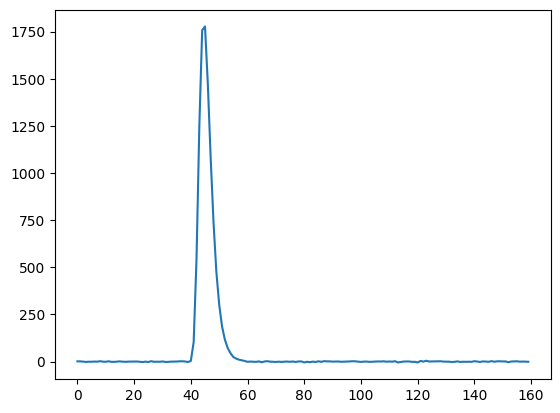

In [12]:
wf_template = build_template_waveform(wfs, t0s, upsample)

In [824]:
num_tests = 100
full_test_wfs = np.random.normal(mean, std, size=(num_tests, out_len))
full_test_wfs_2pe = np.random.normal(mean, std, size=(num_tests, out_len))
full_test_t0s = np.random.uniform(t0_start,t0_start+shift,num_tests) #this indicates where the gumbel peak starts
for i in range(num_tests):
     inject_gumbel(full_test_wfs[i,:], amplitude, full_test_t0s[i], width, full_test_wfs[i,:])
     inject_gumbel(full_test_wfs_2pe[i,:], amplitude*2, full_test_t0s[i], width, full_test_wfs_2pe[i,:])

In [1213]:
pileup_test_wfs = np.random.normal(mean, std, size=(1, out_len))
pileup_test_wfs = np.repeat(pileup_test_wfs, 10, axis=0)

In [1214]:
for i in range(10):
     inject_gumbel(pileup_test_wfs[i,:], amplitude, 40, width, pileup_test_wfs[i,:])
     inject_gumbel(pileup_test_wfs[i,:], amplitude, 41+i, width, pileup_test_wfs[i,:])

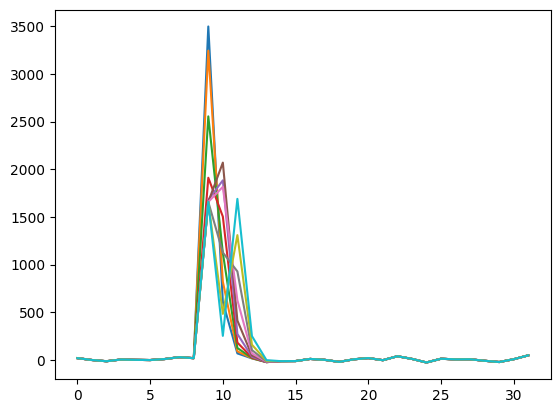

In [1322]:
plt.figure()
for wf in pileup_test_wfs:
    plt.plot(wf[np.arange(0,out_len, 5)])
plt.show()

In [828]:
np.where(out>0.1)[0], full_test_t0s[-1]

(array([11, 12, 13, ..., 26, 27, 28]), 75.90698134373602)

In [829]:
bls = np.random.normal(mean, std, size=(num_tests, wf_len))

In [834]:
test_wfs = full_test_wfs[:,np.arange(0,out_len, upsample)]
test_wfs_2pe = full_test_wfs_2pe[:,np.arange(0,out_len, upsample)]
test_t0s = full_test_t0s/upsample

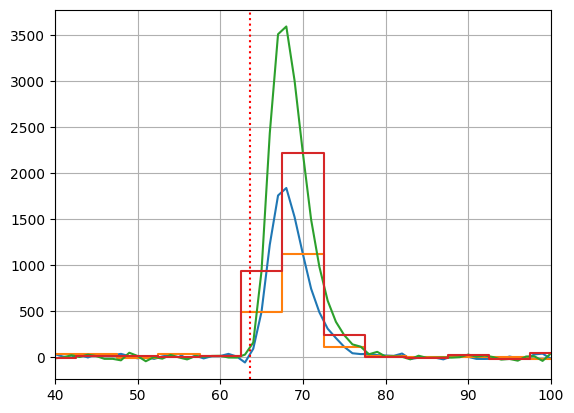

In [835]:
plt.figure()
i=1
plt.plot(full_test_wfs[i])
plt.step(np.arange(0, wf_len)*upsample ,test_wfs[i], where="mid")
plt.plot(full_test_wfs_2pe[i])
plt.step(np.arange(0, wf_len)*upsample ,test_wfs_2pe[i], where="mid")
plt.axvline(full_test_t0s[i], color="red", ls = ":")
plt.xlim([40,100])
plt.grid()
plt.show()

In [16]:
# Initialize A matrix , is it worth constraining so full template must be present?
t0_trials = np.arange(0,wf_len,1/upsample)

In [17]:
from scipy.linalg import hankel

In [18]:
padded_template = np.zeros(out_len)
padded_template[:len(wf_template)] = wf_template

In [436]:
A_upsampled = hankel(padded_template[::-1],np.full(len(padded_template),0))[::-1,:]
A_upsampled = A_upsampled.astype("float32")[:,:-10]

In [437]:
charge_trials = np.sum(A_upsampled, axis =0)

In [438]:
help(inject_gumbel)

Help on GUFunc in module dspeed.processors.pmt_pulse_injector:

inject_gumbel = <numba._GUFunc 'inject_gumbel'>
    Injects a Gumbel distribution into the waveform `wf_in`, modifying it in place in `wf_out`.

    Parameters:
    - wf_in: Input waveform (1D array).
    - a: Amplitude of the Gumbel distribution.
    - t0: Temporal centroid of the Gumbel distribution.
    - beta: Scale parameter (controls spread of the Gumbel distribution).
    - wf_out: Output waveform (1D array), modified by adding the Gumbel distribution.



In [439]:
sampling = np.zeros(out_len, dtype=bool)
sampling[np.arange(0,out_len,upsample, dtype=int)] = True
A = A_upsampled[sampling]

In [440]:
A_upsampled.shape

(160, 150)

In [441]:
A

array([[   3.624791,    0.      ,    0.      , ...,    0.      ,
           0.      ,    0.      ],
       [1777.3542  , 1757.0774  , 1251.0796  , ...,    0.      ,
           0.      ,    0.      ],
       [ 303.2056  ,  476.3818  ,  739.8013  , ...,    0.      ,
           0.      ,    0.      ],
       ...,
       [   0.      ,    0.      ,    0.      , ...,    0.      ,
           0.      ,    0.      ],
       [   0.      ,    0.      ,    0.      , ..., 1251.0796  ,
         541.34595 ,  103.054665],
       [   0.      ,    0.      ,    0.      , ...,  739.8013  ,
        1078.2943  , 1470.5303  ]], dtype=float32)

In [442]:
A.shape

(32, 150)

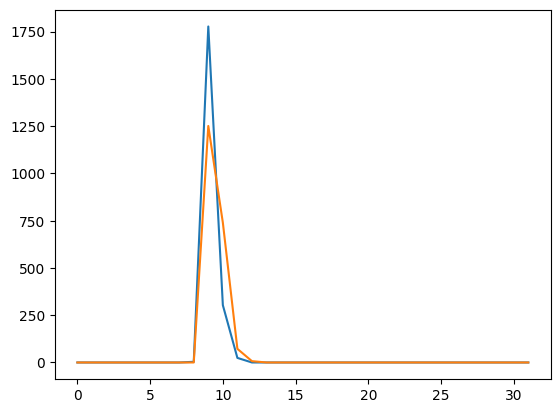

In [443]:
plt.figure()
plt.plot(A[:,40])
plt.plot(A[:,42])
plt.show()

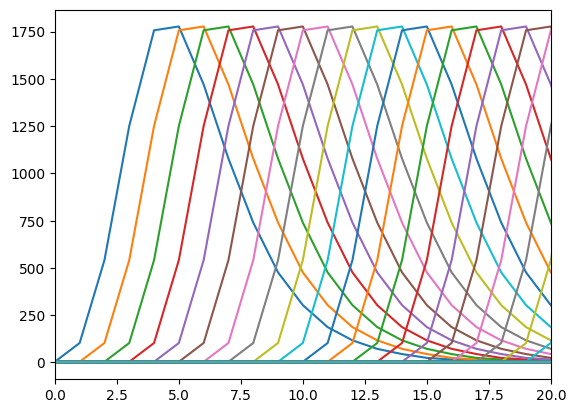

In [1344]:
plt.figure()
for i in A_upsampled.T:
    plt.plot(i)
    #plt.plot(A[:,42])
plt.xlim([0,20])
plt.show()

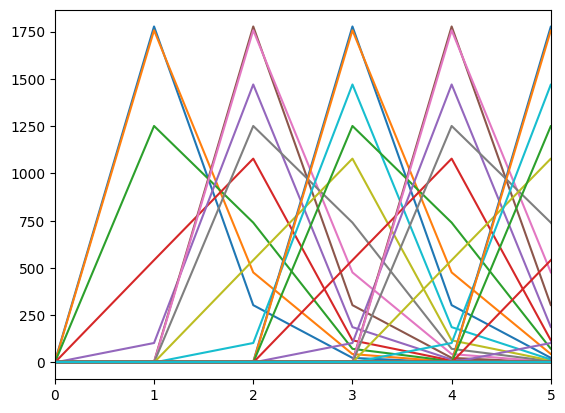

In [445]:
plt.figure()
for i in A.T:
    plt.plot(i)
    #plt.plot(A[:,42])
plt.xlim([0,5])
plt.show()

In [446]:
from numba import njit

In [795]:
#@njit
def merge_close(p, s, a, b, greater_than_min, allowed, n=5):
    solns = np.where(p)[0]

    if len(solns) == 0:
        return p, s
    else:
        groups = []
        current_group = [solns[0]]
        
        for i in range(1, len(solns)):
            # Check if current index is within n of the first index in current group
            if solns[i] - current_group[0] <= n:
                current_group.append(solns[i])
            else:
                # Finalize current group and start new one
                groups.append((min(current_group), max(current_group)))
                current_group = [solns[i]]
        
        # Don't forget the last group
        if len(current_group)>1:
            groups.append((min(current_group), max(current_group)))

     
    if len(groups)>0:
        for entry in groups:
            n, n2 = entry
            init_chi2 = np.sum(((b[greater_than_min] - np.dot(a[greater_than_min,:][:,allowed],s[allowed]))**2 / (b[greater_than_min]+1000)))
            init_dof = (len(b[greater_than_min])-len(np.where(p)[0]))
            init_chi =  init_chi2/ init_dof
            tot = np.sum(s[n:n2+1])
            reses = np.zeros(n2-n + 1, dtype=A.dtype)
            for i,j in enumerate(range(n, n2+1)):
                test = s.copy()
                test[n:n2+1] = 0
                test[j] = tot
                reses[i] = np.sum((b[greater_than_min] - np.dot(a[greater_than_min,:][:,allowed],test[allowed]))**2)

            test[n:n2+1] = 0
            test[np.argmin(reses)+n] = tot
            test_p = p.copy()
            test_p[n:n2+1] = False
            test_p[np.argmin(reses)+n] = True

            mat = numba_ix(ata, pidx[test_p], pidx[test_p])
            if is_singular(mat) and allow_singularity:
                x[:] = np.nan
                return None
                    
            test[test_p] = np.linalg.solve(mat, atb[test_p])

            chi2 = np.sum(((b[greater_than_min] - np.dot(a[greater_than_min,:][:,allowed],test[allowed]))**2)/(b[greater_than_min]+1000))
            dof =(len(b[greater_than_min])-len(np.where(test_p)[0]))
            final_chi =  chi2/dof 

            # print(init_chi2, init_dof, init_chi)
            # print(chi2, dof, final_chi)
            # print(np.where(p)[0], init_chi, final_chi)

            # plt.figure()
            # plt.step(np.arange(0,wf_len,1),b, label="sim wf 1ns sampling", where="mid")
            # #plt.plot(np.dot(a, out), label="reco 1ns sampling")
            # plt.plot(np.dot(a, s), label="reco 1ns sampling")
            # plt.plot(np.dot(a, test), label="reco 1ns sampling")
            # # plt.plot(a[:,78] * 1)
            # plt.plot(a[:,79] * 1)
            # plt.xlim([10,20])
            # plt.show()
            
            
            if final_chi<2*init_chi:
                p = test_p
                s = test
            
    return p, s

In [797]:
200**2 /1000

40.0

In [798]:
out[out>0]

array([0.80111265, 0.15643577], dtype=float32)

14.170816 30 0.4723605473836263
37.674374 31 1.2153023750551286
[77 79] 0.4723605473836263 1.2153023750551286


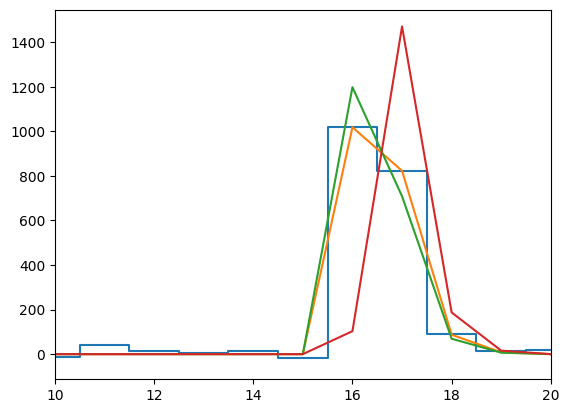

In [796]:
t, t1 = merge_close(out>0, out, A.astype("float32"),  test_wfs[77].astype("float32"), 
            np.ones(wf_len,dtype=bool), 
            np.ones(A.shape[1],dtype=bool), n=10)

In [ ]:
def jax_poisson_chi2(n, mu):
    """JAX implementation of Poisson chi-squared statistic"""
    # Avoid log(0) and division by 0
    mu_safe = jnp.where(mu > 0, mu, 1e-10)
    n_safe = jnp.where(n > 0, n, 1e-10)
    
    # Poisson chi-squared: 2 * sum(mu - n + n*log(n/mu)) where n > 0
    mask = n > 0
    term = jnp.where(mask, 
                     mu - n + n * jnp.log(n_safe / mu_safe),
                     mu)
    return 2 * jnp.sum(term)

@jax.jit
def jax_poisson_nll(n, mu):
    """JAX implementation of Poisson negative log likelihood"""
    # Avoid log(0) and negative mu
    mu_safe = jnp.where(mu > 0, mu, 1e-10)
    
    # Poisson NLL: sum(mu - n*log(mu) + log(n!))
    # We can drop the log(n!) term since it's constant for optimization
    # So NLL = sum(mu - n*log(mu))
    nll_term = mu_safe - n * jnp.log(mu_safe)
    return jnp.sum(nll_term)

In [791]:
full_test_t0s[57]

79.22402391800716

In [792]:
# Run NNLS
optimize_nnls(A.astype("float32"), test_wfs[77].astype("float32"), (A.T@A).astype("float32"), 
              100, 1e-5, False, min_value, 5, 10, out)

1.1578142642974854 3 0.3859380880991618
21.815683364868164 4 5.453920841217041
[77 81] 0.3859380880991618 5.453920841217041
0.5503339767456055 3 0.1834446589152018
21.871763229370117 4 5.467940807342529
[77 80] 0.1834446589152018 5.467940807342529
0.5503339767456055 3 0.1834446589152018
21.871763229370117 4 5.467940807342529
[77 80] 0.1834446589152018 5.467940807342529
0.5503339767456055 3 0.1834446589152018
21.871763229370117 4 5.467940807342529
[77 80] 0.1834446589152018 5.467940807342529
0.5503339767456055 3 0.1834446589152018
21.871763229370117 4 5.467940807342529
[77 80] 0.1834446589152018 5.467940807342529
0.7100595235824585 3 0.2366865078608195
22.9847469329834 4 5.74618673324585
[77 79] 0.2366865078608195 5.74618673324585
0.5323624610900879 3 0.17745415369669595
24.152372360229492 4 6.038093090057373
[77 79] 0.17745415369669595 6.038093090057373
0.5323624610900879 3 0.17745415369669595
24.152372360229492 4 6.038093090057373
[77 79] 0.17745415369669595 6.038093090057373
0.529549

()

In [789]:
out[out>0]

array([0.80111265, 0.15643577], dtype=float32)

In [775]:
np.where(t), t1[t1>0]

((array([77]),), array([0.95754844], dtype=float32))

In [746]:
np.where(out)[0], out[out>0]

(array([74, 79]), array([0.06132831, 0.89967835], dtype=float32))

In [ ]:

i=0
plt.plot( full_test_wfs[i], label="sim wf 1ns sampling")
plt.step(np.arange(0,wf_len)*upsample ,test_wfs[i], where="mid", label="sim wf 5ns sampling")
plt.step(np.arange(0,len(out)) , out*np.amax(full_test_wfs[i]) , label="solution vector")
plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(A_upsampled[:, out>0.5] * out[out>0.5])
#plt.plot(A_upsampled[:,72] * 1)

# plt.xlabel("sample")
# plt.ylabel("amplitude")
#plt.xlim([10*upsample,20*upsample])
plt.xlabel("time (ns)")
plt.ylabel("value (adc)")
plt.legend(frameon=False)
plt.xlim([50,100])
plt.show()

In [584]:
out

array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)

In [749]:
@njit
def merge_in_sample(p, s, a, b, greater_than_min, allowed, group_size=5):
    solns = np.where(p)[0]

    if len(solns) == 0:
        return p, s
    else:
        groups = []
        # Group the array into chunks of specified size
        for i in range(4, len(s), group_size):
            #print(i, i+group_size)
            group = p[i:(i+group_size)]
            # Count True values in this group
            true_count = sum(group)
            
            # Check if this group meets our criteria
            if true_count > 1:
                groups.append((i,i+group_size))

    if len(groups)>0:
        for entry in groups:
            n, n2 = entry
            #print(n,n2)
            tot = np.sum(s[n:n2+1])
            reses = np.zeros(n2-n + 1, dtype=A.dtype)
            for i,j in enumerate(range(n, n2+1)):
                test = s.copy()
                test[n:n2+1] = 0
                test[j] = tot
                reses[i] = np.sum((b[greater_than_min] - np.dot(a[greater_than_min,:][:,allowed],test[allowed]))**2)
            s[n:n2+1] = 0
            s[np.argmin(reses)+n] = tot
            p[n:n2+1] = False
            p[np.argmin(reses)+n] = True
            
    return p, s

In [ ]:
# check all solutions in same sample and choose best \
# compare when adding new solutions

In [ ]:
1 -> 0.2 0.8

In [1287]:
#@njit
def merge_solutions(new, n, n2, a,b, greater_than_min, allowed):
    tot = np.sum(new[n:n2+1])
    reses = np.zeros(n2-n + 1, dtype=a.dtype)
    for i,j in enumerate(range(n, n2+1)):
        test = new.copy()
        test[n:n2+1] = 0
        test[j] = tot
        reses[i] = np.sum((b[greater_than_min] - np.dot(a[greater_than_min,:][:,allowed],test[allowed]))**2)
        #reses[i] = np.sum((b - np.dot(a,test))**2)
    #print(n,n2, reses)
    new[n:n2+1] = 0
    new[np.argmin(reses)+n] = tot
    return new

In [1293]:
#@njit
def compare_solutions(old, new, b, a, greater_than_min, allowed):

    new_tot_energy = np.sum(new) 
    old_tot_energy = np.sum(old)
    
    # if energy has increased by integer amount pass
    if  (new_tot_energy > old_tot_energy +0.5):
        return new, new>0, False

    abs_energy_diff =  np.sum(np.abs(new-old))

    # if total energy diff is not integer check solution
    
    # if new deposit splits energy by non integer amount fail 
    # sum energy deposits
    
    diff = np.abs(old - new)
    nonsignificant_diffs = np.where((diff>0.005))[0]
    new_point = np.where((old==0) & (new != 0))[0]
    if len(new_point) ==0:
        return new, new>0, False
    else:
        new_point = new_point[0]

    # need to look at energy transfer from one deposit to other 
    # diff of integer or 
    
    if len(nonsignificant_diffs) > 0:
        #print('diff')
        # proximity of significant diff to new_point 
        insignificant_diffs = np.where((diff>0.005) & (diff<0.5))[0]
        close_diffs = np.where(np.abs(insignificant_diffs-new_point)<10)[0]

        significant_diffs =  np.where((diff > 0.5))[0]
        
        if len(close_diffs) > 0 :
            for val in close_diffs:
                # eval if new point should replace old or not
                if nonsignificant_diffs[val] != new_point:
                    n = min(nonsignificant_diffs[val], new_point)
                    n2 = max(nonsignificant_diffs[val], new_point)
                else:
                    nearest_point = np.where(old>0)[0][np.argmin(np.abs(new_point - np.where(old>0)[0]))]
                    n = min(nearest_point, new_point)
                    n2 = max(nearest_point, new_point)
                #print(nonsignificant_diffs[val], new_point)
                #print(n,n2)
                new = merge_solutions(new, n, n2, a,b, greater_than_min, allowed)
            return new, new>0, False
            
        elif (abs_energy_diff % 1 >0.2) & (abs_energy_diff % 1 < 0.8):
            #print("abs diff")
            # knock out solutions with large negative shift if we have a non integer energy shift
            # e.g. 0,0,1,0 -> 0,0.8,0.2,0 -> 0,0.8,0,0
            # will then rerun the fit
            
            large_negative = np.where((new-old) < -0.2)[0]

            nearest_point = np.where(old>0)[0][np.argmin(np.abs(large_negative - np.where(old>0)[0]))]
            n = min(nearest_point, new_point)
            n2 = max(nearest_point, new_point)
            #print(n,n2)
            #print(nonsignificant_diffs[val], new_point)
            #print(n,n2)
            new = merge_solutions(new, n, n2, a,b, greater_than_min, allowed)
            #print(large_negative,(new-old)[large_negative])
            #new[large_negative] = 0
            return new, new>0, False

        # if energy split by integer amount look at improvement in 
        # fit?
        else:
            #return new, False
            init_chi2 = np.sum(((b[greater_than_min] - np.dot(a[greater_than_min,:][:,allowed],old[allowed]))**2 / (b[greater_than_min]+1000)))
            init_dof = (len(b[greater_than_min])-len(np.where(old)[0]))
            init_chi =  init_chi2/ init_dof
            
            chi2 = np.sum(((b[greater_than_min] - np.dot(a[greater_than_min,:][:,allowed],new[allowed]))**2)/(b[greater_than_min]+1000))
            dof =(len(b[greater_than_min])-len(np.where(new)[0]))
            final_chi =  chi2/dof 
            if final_chi < init_chi:
                return new, new>0, False
            else:
                return old, old>0, False
        
    else:
        return new, new>0, True    

In [1241]:
old = np.zeros(A.shape[1])
new = np.zeros(A.shape[1])
old[10] =2
new[10] =1
new[11] =1

o,_ = compare_solutions(
    old.astype("float32"),
    new.astype("float32"),
    test_wfs[77].astype("float32"),
    A.astype("float32"),
    np.ones(wf_len, dtype="bool"),
    np.ones(A.shape[1], dtype="bool")
)
np.where(o>0)[0], o[o>0]

ValueError: too many values to unpack (expected 2)

In [1122]:
from __future__ import annotations

import numpy as np
from numba import guvectorize

from dspeed.errors import DSPFatal
from dspeed.utils import numba_defaults_kwargs as nb_kwargs

In [1297]:
# @guvectorize(
#     [
#         "void(float32[:,::1], float32[::1], float32[:,::1], float32, float32, boolean, float32, float32, float32[::1])",
#         "void(float64[:,::1], float64[::1], float64[:,::1], float64, float32, boolean, float32, float32, float64[::1])",
#     ],
#     "(m,n),(m),(n,n),(),(),(),(),(),(n)",
#     #nopython=True,
#     forceobj=True,
#     **nb_kwargs,
# )
def optimize_nnls(
    a: np.ndarray,
    b: np.ndarray,
    ata,
    maxiter: int,
    tol: float,
    allow_singularity: bool,
    min_value: float,
    batch_size:int,
    #merge_range:int,
    x: np.ndarray,
    #verbose=False
) -> None:
    """Solve ``argmin_x || ax - b ||_2`` for ``x>=0``.
    Based on :func:`scipy.optimize.nnls` implementation. Which in turn is based on
    the algorithm in Bro, R. and De Jong, S. (1997), A fast non-negativity-constrained least squares algorithm. J. Chemometrics, 11: 393-401

    Parameters
    ----------
    a : (m, n) ndarray
        Coefficient matrix
    b : (m,) ndarray, float
        Right-hand side vector.
    maxiter: int
        Maximum number of iterations.
    tol: float
        Tolerance value used in the algorithm to assess closeness to zero in
        the projected residual ``(a.T @ (a x - b)`` entries. Increasing this
        value relaxes the solution constraints.
    allow_singularity: bool
        If matrix is not solvable (e.g. because of non full rank caused by
        float precision), no error is raised but all elements of the
        solution vector are set NaN
    x : ndarray
        Solution vector.

    JSON Configuration Example
    --------------------------

    .. code-block :: json

        "nnls_solution": {
            "function": "optimize_nnls",
            "module": "dspeed.processors",
            "args": ["db.coefficient_matrix",
                "wf_blsub",
                "1000", "1e-6", "True"
                "nnls_solution"],
        }
    """

    def numba_ix(arr: np.array, rows: np.array, cols: np.array) -> np.array:
        """
        Numba compatible implementation of arr[np.ix_(rows, cols)] for 2D arrays.
        from https://github.com/numba/numba/issues/5894#issuecomment-974701551
        :param arr: 2D array to be indexed
        :param rows: Row indices
        :param cols: Column indices
        :return: 2D array with the given rows and columns of the input array
        """
        one_d_index = np.zeros(len(rows) * len(cols), dtype=np.int32)
        for i, r in enumerate(rows):
            start = i * len(cols)
            one_d_index[start : start + len(cols)] = cols + arr.shape[1] * r

        arr_1d = arr.reshape((arr.shape[0] * arr.shape[1], 1))
        slice_1d = np.take(arr_1d, one_d_index)
        return slice_1d.reshape((len(rows), len(cols)))

    def is_singular(matrix):
        """
        Returns True if matrix det = 0 i.e. matrix is singular.
        """
        det = np.linalg.det(matrix)
        return abs(det) < np.finfo(np.float64).eps

    m, n = a.shape

    if n != len(x):
        raise DSPFatal(
            "n dimension of coefficient axis doesn't match solution vector length."
        )
    if m != len(b):
        raise DSPFatal(
            "m dimension of coefficient axis doesn't match right-hand vector length."
        )

    ata = np.transpose(a) @ a
    atb = b @ a  # Result is 1D - let NumPy figure it out

    template_max = np.amax(b)
    greater_than_min = b>(0.1*template_max)
    ids = np.where(greater_than_min)[0]
    for i in ids:
        greater_than_min[i-2:i+2] =True

    allowed = np.zeros(A.shape[1], dtype=bool)
    for i in range(A.shape[1]):
        if np.any(A[greater_than_min, i]):
            allowed[i]=True
    
    #if verbose: print(np.where(allowed)[0])

    # Initialize vars
    x[:] = np.zeros(n, dtype=A.dtype)
    s = np.zeros(n, dtype=A.dtype)
    # Inactive constraint switches
    p = np.zeros(n, dtype=np.bool_)
    pidx = np.arange(0, len(p), 1, dtype=np.int32)

    # Projected residual
    w = atb.copy().astype(A.dtype)  # x=0. Skip (-ata @ x) term
    old = s.copy()
    # Overall iteration counter
    # Outer loop is not counted, inner iter is counted across outer spins
    iter = 0
    tried = np.zeros(n, dtype=np.bool_)
    while (not p.all()) and (not tried.all()) and (w[~p * ~tried *allowed] > tol).any():
        # Get the "most" active coeff index and move to inactive set
        k = np.argmax(w * (~p * ~tried *allowed))
        #print(k)
        #if verbose : print("k:",k)
        if batch_size != 0:
            lo = max(0, k-int(batch_size/2))
            hi = min(len(p), k+int(batch_size/2))
            res = b[greater_than_min] - a[greater_than_min,:][:,lo:hi]@x[lo:hi]
            gradient = A[greater_than_min,:][:,lo:hi].T @ res
            sort_grad = np.argsort(gradient)[::-1]
            sort_grad = np.delete(sort_grad, np.where(sort_grad==k)[0])
            order = [k, *np.arange(lo,hi,1)[sort_grad]]
        else:
            order = [k]

        for i in order:
            #print(i)
            p[i] = True
            tried[i] = True
            #print(i, np.where(p)[0])
            # Iteration solution
            s[:] = 0.0
            mat = numba_ix(ata, pidx[p], pidx[p])
    
            # check if matrix has full rank before solving
            if is_singular(mat) and allow_singularity:
                x[:] = np.nan
                return None
    
            s[p] = np.linalg.solve(mat, atb[p])
            #print('d', s[p], np.where(p)[0], s[s!=0])
            #print(np.where(p)[0], s[p])
    
            # Inner loop
            while (iter < maxiter) and len(s[p]) > 0 and (s[p].min() <= min_value):
                #print('a', s[p], old[p],np.where(p)[0], s[s!=0])
                if len(np.where(s[p]>min_value)[0])>1:
                    #print(len(np.where(s[p]>min_value)[0]))
                    s, p,_ = compare_solutions(old, s, b, a, greater_than_min, allowed)
                #print('b', s[p], np.where(p)[0], s[s!=0])
                if s[p].min() >= min_value: break

                if (s[p] <= min_value).any():
                    less_than_mins = np.where(s[p]<= min_value)[0]
                    greater_than_mins = np.where(s[p]> min_value)[0]
                    for val in np.where(p)[0][less_than_mins]:
                        samps = np.where(np.abs(greater_than_mins-val)<5)[0]
                        if len(samps)>0:
                            closest = samps[np.argmin(samps)]
                            #print(val, closest)
                            #print("here", min(val,closest), 
                            #                max(val, closest))
                            s = merge_solutions(s, 
                                            min(val,closest), 
                                            max(val, closest), 
                                            a,
                                            b, 
                                            greater_than_min, 
                                            allowed)
                            
                            
                    
                iter += 1
                inds = p * (s <= min_value) # maybe need to change this 
                alpha = (x[inds] / (x[inds] - s[inds])).min()
                #if alpha <0: alpha=0
                x *= 1 - alpha
                x += alpha * s
                #if verbose : print(x[p])
                p[x <= min_value] = False
    
                mat = numba_ix(ata, pidx[p], pidx[p])
                if is_singular(mat) and allow_singularity:
                    x[:] = np.nan
                    return None
                s[p] = np.linalg.solve(mat, atb[p])
                s[~p] = 0
                old = s.copy()  
                #print('c', s[p], np.where(p)[0], s[s!=0])
                
            #print("f", s[p], np.where(p)[0], s[s!=0])
            if (len(np.where(s>0)[0]) != len(np.where(old>0)[0])) or (np.where(s>0)[0] != np.where(old>0)[0]).any():
                #print(old[old!=0], s[s!=0])
                new_s, p,_= compare_solutions(old, s, b, a, greater_than_min, allowed)
                #print("h", new_s[p])
                if (new_s != s).all():
                    mat = numba_ix(ata, pidx[p], pidx[p])
                    s[p] = np.linalg.solve(mat, atb[p])
            x[allowed] = s[allowed]
            w[allowed] = atb[allowed] - ata[allowed,:][:,allowed] @ x[allowed]
            old = s.copy()  
            #print("i", s[p], np.where(p)[0], s[s!=0])

        if iter == maxiter:
            return None
    #print(s[p], np.where(p)[0], s[s!=0])

In [1313]:
optimize_nnls(A.astype("float32"), test_wfs[52].astype("float32"), ata, 
                  100, 1e-5, False, 0.3, 0,out)
out[out!=0]

array([0.66580874, 0.474214  ], dtype=float32)

In [1275]:
40, 47

(40, 47)

In [ ]:
    optimize_nnls(A.astype("float32"), w.astype("float32"), ata, 
                  100, 1e-5, False, 0.3, 0,out)

In [1315]:
optimize_nnls(A.astype("float32"), test_wfs[52].astype("float32"), ata, 
              100, 1e-5, False, 0.3, 5, out)
out[out!=0]

array([1.0200353], dtype=float32)

In [1276]:
optimize_nnls(A.astype("float32"), pileup_test_wfs[-3][np.arange(0,out_len,5)].astype("float32"), ata, 
              100, 1e-5, False, 0.3, 5, out)

41
f [1.0522628] [41] [1.0522628]
h [1.0522628]
i [1.0522628] [41] [1.0522628]
41
f [1.0522628] [41] [1.0522628]
i [1.0522628] [41] [1.0522628]
40
a [-4.3208323  5.310838 ] [0.        1.0522628] [40 41] [-4.3208323  5.310838 ]
b [-4.3208323  5.310838 ] [40 41] [-4.3208323  5.310838 ]
c [1.0522628] [41] [1.0522628]
f [1.0522628] [41] [1.0522628]
i [1.0522628] [41] [1.0522628]
42
a [-0.4097521  1.898429 ] [1.0522628 0.       ] [41 42] [-0.4097521  1.898429 ]
b [-0.4097521  1.898429 ] [41 42] [-0.4097521  1.898429 ]
c [1.4042904] [42] [1.4042904]
f [1.4042904] [42] [1.4042904]
i [1.4042904] [42] [1.4042904]
39
a [-0.32292682  1.706091  ] [0.        1.4042904] [39 42] [-0.32292682  1.706091  ]
b [-0.32292682  1.706091  ] [39 42] [-0.32292682  1.706091  ]
c [1.4042904] [42] [1.4042904]
f [1.4042904] [42] [1.4042904]
i [1.4042904] [42] [1.4042904]
50
f [1.3752844  0.46164617] [42 50] [1.3752844  0.46164617]
42 50 [1107024.8 1685133.6 4982051.  7438333.  7164716.  4306152.  3885147.2
 6827647

IndexError: index 0 is out of bounds for axis 0 with size 0

In [1231]:
for w in pileup_test_wfs:
    optimize_nnls(A.astype("float32"), w[np.arange(0,out_len,5)].astype("float32"), ata, 
              100, 1e-5, False, 0.3, 0, out)
    print(out[out!=0])

[1.968356]
[1.8369079]
[1.9049835]
[1.6598647]
[2.022388]
[1.3243966  0.63702095]
[1.9923034]
[1.4042904]
[1.1551677  0.81780505]
[0.9369152  0.93411434]


In [1198]:
optimize_nnls(A.astype("float32"), test_wfs_2pe[17].astype("float32"), ata, 
              100, 1e-5, False, 0.3, 0, out)
out[out!=0]

array([1.9858768], dtype=float32)

In [1113]:
# iterative approach
# add new sample look at effect on old samples - have they shifted away from integers by small amounts
# if so remove new solution
# terminate if no improvement




In [1124]:
out = np.zeros(A.shape[1], dtype="float32")
ata = (A.T@A).astype("float32"), 

In [1125]:
full_test_t0s[15]

74.62918308345783

In [1126]:
# Run NNLS

optimize_nnls(A.astype("float32"), test_wfs[24].astype("float32"), ata,
              100, 1e-5, False, min_value, 0, out)

()

In [1127]:
out[out!=0], np.where(out)

(array([1.0402911], dtype=float32), (array([75]),))

[0.98912865] [75]


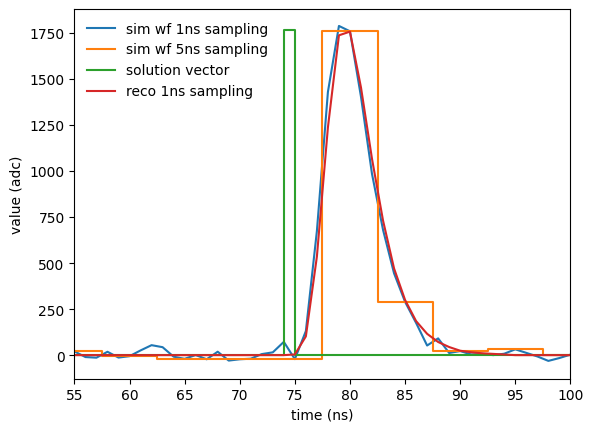

In [1060]:
plt.figure()
i=77
# out=np.zeros(A.shape[1], dtype="float32")
# optimize_nnls(A.astype("float32"), test_wfs[i].astype("float32"), (A.T@A).astype("float32"), 
#               100, 1e-5, False, min_value, 0, 0, 5,out)
# out[out<0.4] = 0
print(out[out>0], np.where(out)[0])
plt.plot( full_test_wfs[i], label="sim wf 1ns sampling")
plt.step(np.arange(0,wf_len)*upsample ,test_wfs[i], where="mid", label="sim wf 5ns sampling")
plt.step(np.arange(0,len(out)) , out*np.amax(full_test_wfs[i]) , label="solution vector")
plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(A_upsampled[:, out>0.5] * out[out>0.5])
#plt.plot(A_upsampled[:,72] * 1)

# plt.xlabel("sample")
# plt.ylabel("amplitude")
#plt.xlim([10*upsample,20*upsample])
plt.xlabel("time (ns)")
plt.ylabel("value (adc)")
plt.legend(frameon=False)
plt.xlim([55,100])
plt.show()

[1.1368362 0.9368558] [39 50]


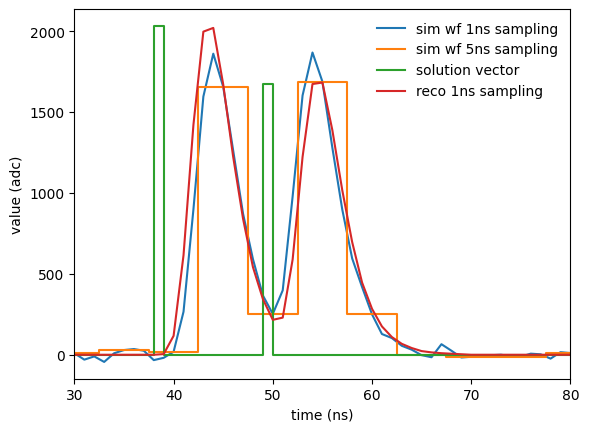

In [1328]:
# for w in pileup_test_wfs:
#     optimize_nnls(A.astype("float32"), w[np.arange(0,out_len,5)].astype("float32"), ata, 
#               100, 1e-5, False, 0.3, 0, out)
#     print(out[out!=0])
plt.figure()
i=9
wf = pileup_test_wfs[i][np.arange(0,out_len,5)].astype("float32")
out=np.zeros(A.shape[1], dtype="float32")
optimize_nnls(A.astype("float32"), wf, (A.T@A).astype("float32"), 
              100, 1e-5, False, 0.3, 5,out)
out[out<0.4] = 0
print(out[out>0], np.where(out)[0])
plt.plot( pileup_test_wfs[i], label="sim wf 1ns sampling")
plt.step(np.arange(0,wf_len)*upsample ,wf, where="mid", label="sim wf 5ns sampling")
plt.step(np.arange(0,len(out)) , out*np.amax(full_test_wfs[i]) , label="solution vector")
plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(A_upsampled[:, out>0.5] * out[out>0.5])
#plt.plot(A_upsampled[:,72] * 1)

# plt.xlabel("sample")
# plt.ylabel("amplitude")
#plt.xlim([10*upsample,20*upsample])
plt.xlabel("time (ns)")
plt.ylabel("value (adc)")
plt.legend(frameon=False)
plt.xlim([30,80])
plt.show()

In [474]:
np.where(out)[0], out[out>0], full_test_t0s[i]

(array([79]), array([0.78507745], dtype=float32), 79.22402391800716)

In [36]:
from iminuit.cost import poisson_chi2

In [37]:
import jax

In [38]:
from iminuit import Minuit

In [39]:
import jax.numpy as jnp
from jax import jit

In [40]:
@jax.jit
def jax_poisson_chi2(n, mu):
    """JAX implementation of Poisson chi-squared statistic"""
    # Avoid log(0) and division by 0
    mu_safe = jnp.where(mu > 0, mu, 1e-10)
    n_safe = jnp.where(n > 0, n, 1e-10)
    
    # Poisson chi-squared: 2 * sum(mu - n + n*log(n/mu)) where n > 0
    mask = n > 0
    term = jnp.where(mask, 
                     mu - n + n * jnp.log(n_safe / mu_safe),
                     mu)
    return 2 * jnp.sum(term)

@jax.jit
def jax_poisson_nll(n, mu):
    """JAX implementation of Poisson negative log likelihood"""
    # Avoid log(0) and negative mu
    mu_safe = jnp.where(mu > 0, mu, 1e-10)
    
    # Poisson NLL: sum(mu - n*log(mu) + log(n!))
    # We can drop the log(n!) term since it's constant for optimization
    # So NLL = sum(mu - n*log(mu))
    nll_term = mu_safe - n * jnp.log(mu_safe)
    return jnp.sum(nll_term)

@jax.jit
def cost_base(weights, A, wf, min_val):
    # Create mask for weights above minimum
    mask = weights > min_val
    # Apply mask and compute weighted sum in one operation
    weighted_contributions = A * (weights * mask)[None, :]  # Broadcasting
    output = jnp.sum(weighted_contributions, axis=1)
    r = jax_poisson_chi2(wf, output)
    return r

In [475]:
@jax.jit
def gaussian_pull_to_integers(weights, sigma=0.1):
    """Gaussian pull term to encourage integer values"""
    # Distance to nearest integer
    nearest_int = jnp.round(weights)
    deviation = weights - nearest_int
    
    # Gaussian penalty: (deviation/sigma)^2 / 2
    pull_term = jnp.sum(deviation**2) / (2 * sigma**2)
    return pull_term

In [42]:
@jax.jit
def asymmetric_integer_pull(weights, sigma_pos=0.1, sigma_zero=0.05):
    """Asymmetric pull: stronger pull to zero for small values"""
    nearest_int = jnp.round(weights)
    deviation = weights - nearest_int
    
    # Use different sigma based on whether nearest integer is zero
    sigma = jnp.where(nearest_int == 0, sigma_zero, sigma_pos)
    pull_term = jnp.sum(deviation**2 / (2 * sigma**2))
    return pull_term

In [43]:
@jax.jit
def cost_base_pull(weights, A, wf, min_val, pull_strength=1.0, pull_sigma=0.2):
    # Create mask for weights above minimum
    mask = weights > min_val
    # Apply mask and compute weighted sum in one operation
    weighted_contributions = A * (weights * mask)[None, :]  # Broadcasting
    output = jnp.sum(weighted_contributions, axis=1)
    r = jax_poisson_nll(wf, output) + pull_strength*jnp.cos(1/(2*jnp.pi))#gaussian_pull_to_integers(weights, pull_sigma)
    return r

In [44]:
-jnp.cos(1/2*jnp.pi)

Array(4.371139e-08, dtype=float32, weak_type=True)

In [45]:
@nb.jit
def nb_poisson_chi2(n, mu):
    """JAX implementation of Poisson chi-squared statistic"""
    # Avoid log(0) and division by 0
    mu_safe = np.where(mu > 0, mu, 1e-10)
    n_safe = np.where(n > 0, n, 1e-10)
    
    # Poisson chi-squared: 2 * sum(mu - n + n*log(n/mu)) where n > 0
    mask = n > 0
    term = np.where(mask, 
                     mu - n + n * np.log(n_safe / mu_safe),
                     mu)
    # add a gaussian pull term to integers
    # add a penalty term for splitting in same sample
    return 2 * np.sum(term)

In [46]:
@nb.jit
def nb_cost_base(weights, A, wf, min_val):
    # Create mask for weights above minimum
    mask = weights > min_val
    # Apply mask and compute weighted sum in one operation
    weighted_contributions = A * (weights * mask)[None, :]  # Broadcasting
    output = np.sum(weighted_contributions, axis=1)
    r = nb_poisson_chi2(wf, output)
    return r

In [47]:
def fit_waveform(wf):
    # Usage:
    cost= lambda x: cost_base_pull(x, A, wf, 0.4, 1000, 0.4)
    
    cost.errordef = Minuit.LEAST_SQUARES
    cost.ndata = np.prod(A.shape[0])

    starts = np.repeat(wf/np.amax(wf_template),5)
    starts[starts<0.4] = 0
    starts[:-5] = starts[5:]
    starts[-5:0] = 0
    fixed = starts==0
    
    #starts = np.ones(A.shape[1])
    m = Minuit(cost, starts)#grad = jax.grad(cost)
    m.print_level = -1
    m.strategy=0
    m.fixed = fixed
    m.limits = (0, None)
    m.simplex().migrad() #
    out = np.array(m.values)
    out[out<0.4] = 0
    return out

In [48]:
out = fit_waveform(test_wfs[17])

In [49]:
%%time
outs = []
for i, w in enumerate(test_wfs):
    out = fit_waveform(w.astype("float32"))
    outs.append(out)
    print(i, np.where(out>0)[0], out[out>0])

0 [57] [1.1008236]
1 [65 67] [0.40012534 0.69251012]
2 [78] [1.32238144]
3 [77] [1.11422125]
4 [73 77] [0.82309195 0.40005022]
5 [72] [1.08129045]
6 [67] [1.10960169]
7 [62] [1.04801293]
8 [60] [0.84532372]
9 [72] [1.0130142]
10 [76 77] [0.66842449 0.4006741 ]
11 [62] [1.09797564]
12 [65 68] [0.70198285 0.40032399]
13 [70] [0.88586988]
14 [55 56] [0.40000869 0.40002965]
15 [57] [1.09384453]
16 [57] [1.02308324]
17 [56 59] [0.47817425 0.46285842]
18 [60] [1.05436723]
19 [60] [0.7953263]
20 [56] [0.9703708]
21 [75 79] [0.94468607 0.40000139]
22 [73] [1.31973721]
23 [65] [0.84010954]
24 [68] [1.13688738]
25 [57] [1.05627367]
26 [70] [0.81409111]
27 [60] [0.84973533]
28 [75] [1.03284626]
29 [60] [0.8577297]
30 [55 57] [0.42559081 0.65567154]
31 [58] [1.08708134]
32 [80 82] [0.68699608 0.40000075]
33 [60] [0.79556208]
34 [70] [0.79980244]
35 [76 80] [0.49052732 0.4002132 ]
36 [62] [1.06451177]
37 [58] [1.22401712]
38 [70 72] [0.40225213 0.63434603]
39 [75 79] [0.64895639 0.40007778]
40 [77]

In [50]:
A.shape

(32, 160)

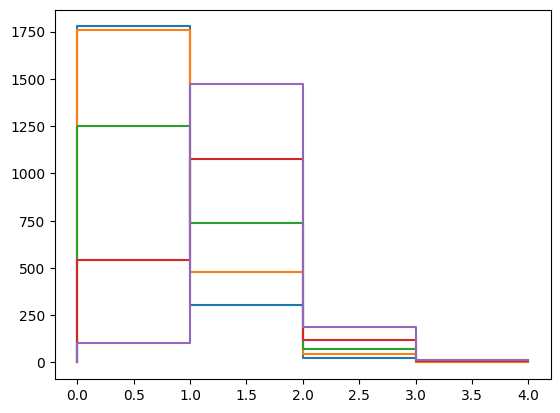

In [51]:
plt.figure()
for a in A.T[:5]:
    plt.step(np.arange(5),a[:5])
plt.show()

In [52]:
test = A.T[:5,:5]
test2 = np.array([3.4, 7.2, 19.7])

In [53]:
test.shape

(5, 5)

In [54]:
test2//5, test2%5

(array([0., 1., 3.]), array([3.4, 2.2, 4.7]))

In [55]:
(test[test2%5,:]).shape #+ (test2//5)[:,None]

IndexError: arrays used as indices must be of integer (or boolean) type

In [56]:
test3=np.zeros((len(test2),32))

In [57]:
test3.shape

(3, 32)

In [58]:
(test2//5)

array([0., 1., 3.])

In [391]:
test[test2%5,i]
for i,j in enumerate(test2//5):
    test3[i,j:j+test.shape[1]] = test[test2[i]%5,:]

In [393]:
test3.shape

(3, 32)

In [59]:
@jax.jit
def cost_base_t0s(y, A,  wf, min_val):
    weights = y[:len(wf)]
    t0s = y[len(wf):]
    # Create mask for weights above minimum
    mask = weights > min_val
    # Apply mask and compute weighted sum in one operation
    ts = (t0s * mask )


    mat = jnp.zeros((len(ts),len(wf)))
    for i,j in enumerate((ts//A.shape[1]).astype(int)):
        for k in range(A.shape[1]):
            mat.at[i,j+k].set(A[(ts[i]%5).astype(int),k])

    weighted_contributions = mat * (weights * mask)[None, :]  # Broadcasting
    output = jnp.sum(weighted_contributions, axis=1)
    r = jax_poisson_nll(wf, output)
    return r

In [60]:
def fit_waveform_t0s(wf):
    # Usage:
    cost= lambda x: cost_base(x, A.T[:5][:5], wf, 0.4)
    
    cost.errordef = Minuit.LEAST_SQUARES
    cost.ndata = np.prod(A.shape[0])

    starts = wf/np.amax(wf_template)
    starts[starts<0.4] = 0
    starts[:-1] = starts[1:]
    starts[-1:0] = 0
    fixed = starts==0
    t0s = np.where(~fixed)[0]+2
    
    #starts = np.ones(A.shape[1])
    m = Minuit(cost, starts, t0s)#grad = jax.grad(cost)
    m.print_level = -1
    m.strategy=0
    m.fixed = fixed
    m.limits = (0, None)
    m.simplex().migrad() #
    out = np.array(m.values)
    out[out<0.4] = 0
    return out

In [61]:
cost= lambda x: cost_base_t0s(x, A.T[:5][:5], test_wfs[17], 0.4)
    
cost.errordef = Minuit.LEAST_SQUARES
cost.ndata = np.prod(A.shape[0])

starts = test_wfs[17]/np.amax(wf_template)
starts[starts<0.4] = 0
starts[:-1] = starts[1:]
starts[-1:0] = 0
fixed = starts==0
t0s = (np.arange(0,wf_len) *5)+2

In [62]:
len(starts), len(t0s)

(32, 32)

In [63]:
m = Minuit(cost, np.concatenate([starts, t0s]), grad = jax.grad(cost))

In [64]:
m.print_level = -1
m.strategy=0
m.fixed = np.concatenate([fixed,fixed])
m.limits[:wf_len] = (0, None)
m.limits[wf_len:] = [(i*5, (i+1)*5) for i in range(wf_len)]


In [65]:
m.simplex().migrad() #


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 4.309e+04 (χ²/ndof = 1539.0)│              Nfcn = 369              │
│ EDM = nan (Goal: 0.0002)         │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│         INVALID Minimum          │   ABOVE EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│           Hesse FAILED           │       Covariance NOT pos. def.       │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬──────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼──────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ x0   │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 1 │ x1   │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 2 │ x2   │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 3 │ x3   │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 4 │ x4   │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 5 │ x5   │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 6 │ x6   │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 7 │ x7   │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 8 │ x8   │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 9 │ x9   │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 10│ x10  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 11│ x11  │ 4.9887e-1 │ 0.0000e-1 │            │            │    0    │         │       │
│ 12│ x12  │ 5.1979e-1 │ 0.0000e-1 │            │            │    0    │         │       │
│ 13│ x13  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 14│ x14  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 15│ x15  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 16│ x16  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 17│ x17  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 18│ x18  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 19│ x19  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 20│ x20  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 21│ x21  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 22│ x22  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 23│ x23  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 24│ x24  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 25│ x25  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 26│ x26  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 27│ x27  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 28│ x28  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 29│ x29  │    0.0    │    0.1    │            │            │    0    │         │  yes  │
│ 30│ x30  │    0.0    │    0.1    │            │            │    0    │         │  

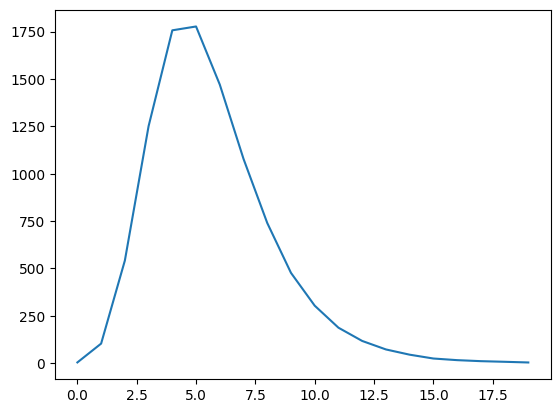

In [66]:
plt.figure()
plt.plot(wf_template)
plt.show()

In [67]:
# alternative fit, fit in each block with 2 params, t0 and amp

In [68]:
len(test_wfs)

100

In [289]:
@guvectorize(
    [
        "void(float32[:,::1], float32[::1], float32[:,::1], float32, float32, boolean, float32, float32, float32[::1])",
        "void(float64[:,::1], float64[::1], float64[:,::1], float64, float32, boolean, float32, float32, float64[::1])",
    ],
    "(m,n),(m),(n,n),(),(),(),(),(),(n)",
    nopython=True,
    **nb_kwargs,
)
def optimize_nnls_base(
    a: np.ndarray,
    b: np.ndarray,
    ata: np.ndarray,
    maxiter: int,
    tol: float,
    allow_singularity: bool,
    min_value: float,
    lmb: float,
    x: np.ndarray,
) -> None:
    """Solve ``argmin_x || ax - b ||_2`` for ``x>=0``.
    Based on :func:`scipy.optimize.nnls` implementation. Which in turn is based on
    the algorithm in Bro, R. and De Jong, S. (1997), A fast non-negativity-constrained least squares algorithm. J. Chemometrics, 11: 393-401

    Parameters
    ----------
    a : (m, n) ndarray
        Coefficient matrix
    b : (m,) ndarray, float
        Right-hand side vector.
    maxiter: int
        Maximum number of iterations.
    tol: float
        Tolerance value used in the algorithm to assess closeness to zero in
        the projected residual ``(a.T @ (a x - b)`` entries. Increasing this
        value relaxes the solution constraints.
    allow_singularity: bool
        If matrix is not solvable (e.g. because of non full rank caused by
        float precision), no error is raised but all elements of the
        solution vector are set NaN
    min_value: float
        Threshold for noise reduction
    lmb : float
        L1 penalty to enforce sparsity in the solution.
    x : ndarray
        Solution vector.

    JSON Configuration Example
    --------------------------

    .. code-block :: json

        "nnls_solution": {
            "function": "optimize_nnls",
            "module": "dspeed.processors",
            "args": ["db.coefficient_matrix",
                "wf_blsub",
                "1000", "1e-6", "True", 0.3, 3e4,
                "nnls_solution"],
        }
    """

    def numba_ix(arr: np.array, rows: np.array, cols: np.array) -> np.array:
        """
        Numba compatible implementation of arr[np.ix_(rows, cols)] for 2D arrays.
        from https://github.com/numba/numba/issues/5894#issuecomment-974701551
        :param arr: 2D array to be indexed
        :param rows: Row indices
        :param cols: Column indices
        :return: 2D array with the given rows and columns of the input array
        """
        one_d_index = np.zeros(len(rows) * len(cols), dtype=np.int32)
        for i, r in enumerate(rows):
            start = i * len(cols)
            one_d_index[start : start + len(cols)] = cols + arr.shape[1] * r

        arr_1d = arr.reshape((arr.shape[0] * arr.shape[1], 1))
        slice_1d = np.take(arr_1d, one_d_index)
        return slice_1d.reshape((len(rows), len(cols)))

    def is_singular(matrix, eps=10**-12):
        """
        Returns True if matrix det = 0 i.e. matrix is singular.
        """
        # For larger matrices, check condition number
        try:
            # Compute the condition number using SVD-based approach
            s = np.linalg.svd(matrix, compute_uv=False)
            print(s)
            cond = max(s) / min(s) if min(s) > 0 else np.inf
            return cond > 1e12 or min(s) < eps
        except:
            # Fallback to determinant if SVD fails
            det = np.linalg.det(matrix)
            return abs(det) < eps
        # det = np.linalg.det(matrix)
        # return abs(det) < np.finfo(A.dtype).eps

    m, n = a.shape

    if n != len(x):
        msg = "n dimension of coefficient axis doesn't match solution vector length."
        raise DSPFatal()
    if m != len(b):
        msg = "m dimension of coefficient axis doesn't match right-hand vector length."
        raise DSPFatal(msg)

    # ata = np.transpose(a) @ a
    atb = b @ a - lmb  # Result is 1D - let NumPy figure it out

    # Initialize vars
    x[:] = np.zeros(n, dtype=A.dtype)
    s = np.zeros(n, dtype=A.dtype)
    # Inactive constraint switches
    p = np.zeros(n, dtype=np.bool_)
    pidx = np.arange(0, len(p), 1, dtype=np.int32)

    # Projected residual
    w = atb.copy().astype(A.dtype)  # x=0. Skip (-ata @ x) term

    # Overall iteration counter
    # Outer loop is not counted, inner iter is counted across outer spins
    iter = 0
    while (not p.all()) and (w[~p] > tol).any():
        # Get the "most" active coeff index and move to inactive set
        k = np.argmax(w * (~p))
        p[k] = True

        # Iteration solution
        s[:] = 0.0
        mat = numba_ix(ata, pidx[p], pidx[p])

        # check if matrix has full rank before solving
        if is_singular(mat) and allow_singularity:
            x[:] = np.nan
            return

        s[p] = np.linalg.solve(mat, atb[p])

        # Inner loop
        while (iter < maxiter) and (s[p].min() <= min_value):
            iter += 1
            inds = p * (s <= min_value)
            denominator = x[inds] - s[inds]
            # Only compute alpha where denominator is not near zero
            valid_mask = np.abs(denominator) > np.finfo(np.float64).eps
            if not valid_mask.any():
                # If no valid denominators, break to avoid infinite loop
                break
            alpha_candidates = np.where(valid_mask, x[inds] / denominator, np.inf)
            alpha = alpha_candidates.min()
            
            # Clamp alpha to reasonable range to prevent overflow
            alpha = max(0.0, min(alpha, 1.0))
            x *= 1 - alpha
            x += alpha * s
            p[x <= tol] = False

            mat = numba_ix(ata, pidx[p], pidx[p])
            if is_singular(mat) and allow_singularity:
                x[:] = np.nan
                return

            s[p] = np.linalg.solve(mat, atb[p])
            s[~p] = 0

        x[:] = s[:]
        w[:] = atb - ata @ x

        if iter == maxiter:
            return


TypingError: Failed in nopython mode pipeline (step: nopython frontend)
No implementation of function Function(<built-in function min>) found for signature:
 
 >>> min(Tuple(array(float32, 2d, F), array(float32, 1d, C), array(float32, 2d, F)))
 
There are 8 candidate implementations:
      - Of which 4 did not match due to:
      Overload of function 'min': File: <numerous>: Line N/A.
        With argument(s): '(Tuple(array(float32, 2d, F), array(float32, 1d, C), array(float32, 2d, F)))':
       No match.
      - Of which 2 did not match due to:
      Overload in function 'indval_min': File: numba/cpython/old_builtins.py: Line 568.
        With argument(s): '(Tuple(array(float32, 2d, F), array(float32, 1d, C), array(float32, 2d, F)))':
       Rejected as the implementation raised a specific error:
         TypingError: missing a required argument: 'indval2'
  raised from /Users/georgemarshall/mint-analysis/.venv/lib/python3.12/site-packages/numba/core/typing/templates.py:791
      - Of

In [286]:
ata = A.T@A
ata += np.eye(ata.shape[0]) * 1e-10

In [287]:
%%time
outs = []
out = np.zeros(A.shape[1], dtype="float32")
#ata = (A.T@A).astype("float32")
for i, w in enumerate(bls):
    # Run NNLS
    optimize_nnls_base(A.astype("float32"), w.astype("float32"), ata, 
                  100, 1e-5, True, 0, 0, out)
    outs.append(out.copy())
    print(i)
    print(i, np.where(out>0.1)[0], out[out>0.1])

[3251523.2]
[3316251.8 3251523.2]
[3337396.5 3316251.8 3230378.5]
[3337396.5 3316251.8 3316251.8 3230378.5]
[4152183.  3316251.8 3316251.8 3251514.8 2415600.8]
[4152183.  3316251.8 3316251.8 3251525.  3251512.8 2415600.8]
[4152183.  3316251.8 3316251.8 3251525.  3251523.2 3251512.8 2415600.8]
[4152183.  3316251.8 3316251.8 3295726.  3251525.  3251512.8 3207320.5
 2415600.8]
[4152183.  3316251.8 3316251.8 3295726.  3255658.8 3251514.5 3207320.5
 2415600.8 2168944. ]
[4152183.  3810584.8 3316251.8 3295726.  3255658.8 3251514.5 3207320.5
 2415600.8 2168944.  1713957. ]
[5452704.    4152183.    3810584.8   ... 2168944.    1713957.
    8337.692]
[4152183.  3810584.8 3316251.8 3255658.8 3252302.  3251514.5 2415600.8
 2207511.2 2168944.  1713957. ]
[6.0168290e+06 3.8105848e+06 3.3162518e+06 ... 2.1689440e+06 1.7139570e+06
 2.2518650e+03]
[3813219.8 3810584.8 3316251.8 3255658.8 3252302.  3249111.2 2207511.2
 2168944.  1713957.  1713734.1]
[4153183.5 3812816.8 3810584.8 ... 2164788.5 1713957. 

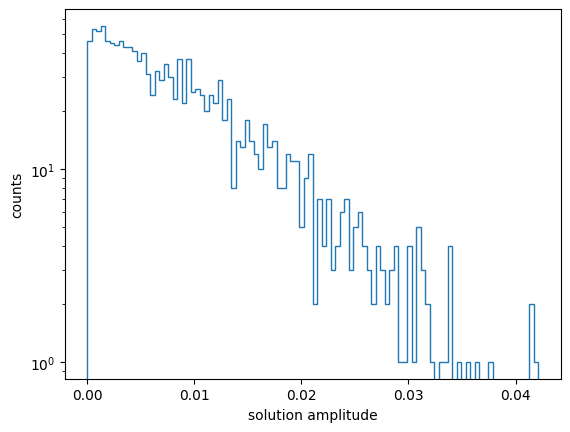

In [232]:
plt.figure()
res = np.array(outs).flatten()
plt.hist(res[res>0], bins=100, histtype="step")
plt.xlabel("solution amplitude")
plt.ylabel("counts")
plt.yscale("log")
plt.show()

In [233]:
min_value = 0.05

In [316]:
ata = (A.T@A).astype("float32")

In [330]:
%%time
outs = []
out = np.zeros(A.shape[1], dtype="float32")

for i, w in enumerate(test_wfs):
    # Run NNLS
    optimize_nnls_base(A.astype("float32"), w.astype("float32"), ata, 
                  100, 1e-5, False, min_value, 0, out)
    outs.append(out.copy())
    print(i, np.where(out>0)[0], out[out>0])

[3316251.8]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 2457866. ]
[4174637.5 3251523.2 2457866. ]
[4174637.5 24578

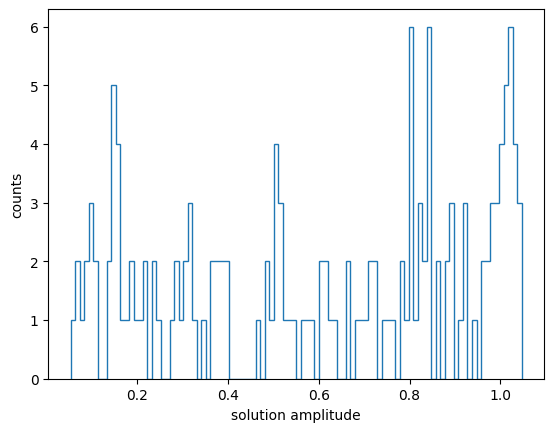

In [331]:
plt.figure()
res = np.array(outs).flatten()
plt.hist(res[res>0], bins=100, histtype="step")
plt.xlabel("solution amplitude")
plt.ylabel("counts")
plt.show()

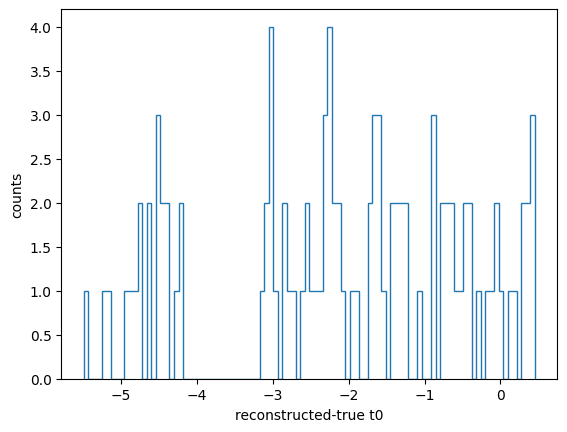

In [332]:
plt.figure()
plt.hist([np.where(out>0)[0][0]-full_test_t0 for out,full_test_t0  in zip(outs, full_test_t0s)], bins=100, histtype="step")
plt.xlabel("reconstructed-true t0")
plt.ylabel("counts")
plt.show()

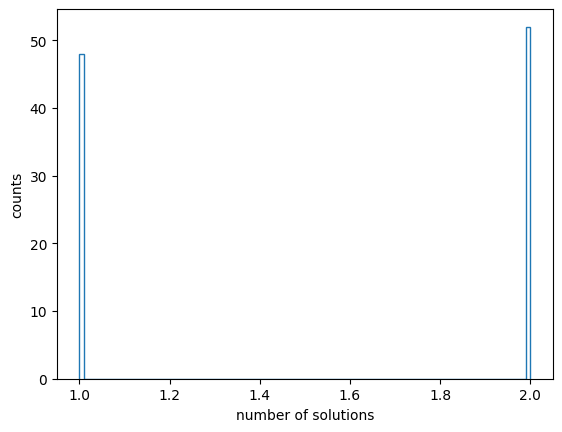

In [333]:
plt.figure()
plt.hist([len(out[out>0]) for out in outs], bins=100, histtype="step")
plt.xlabel("number of solutions")
plt.ylabel("counts")
plt.show()

In [482]:
#out=np.zeros(A.shape[1], dtype="float32")
optimize_nnls(A.astype("float32"), test_wfs[57].astype("float32"), (A.T@A).astype("float32"), 
              100, 1e-5, False, min_value, 5, out)

()

In [484]:
np.where(out>0)[0], out[out>0]

(array([74, 79]), array([0.05263293, 0.8995451 ], dtype=float32))

In [493]:
np.arange(0,out_len, 5)

array([  0,   5,  10, ..., 145, 150, 155])

In [1312]:
optimize_nnls(A.astype("float32"), test_wfs[52].astype("float32"), ata, 
                  100, 1e-5, False, 0.3, 0,out)
out[out!=0]

array([0.66580874, 0.474214  ], dtype=float32)

In [1316]:
%%time
outs = []
out = np.zeros(A.shape[1], dtype="float32")
ata = (A.T@A).astype("float32")
for i, w in enumerate(test_wfs):
    # Run NNLS
    optimize_nnls(A.astype("float32"), w.astype("float32"), ata, 
                  100, 1e-5, False, 0.3, 5,out)
    outs.append(out.copy())
    print(i, np.where(out>0)[0], out[out!=0])

0 [70] [0.9421481]
1 [63] [1.0129976]
2 [60] [0.96258914]
3 [78] [1.0395813]
4 [78] [0.9620779]
5 [77] [1.0405029]
6 [77] [0.9897226]
7 [68] [0.9624263]
8 [72] [0.9846682]
9 [70] [0.9784392]
10 [56] [1.0099396]
11 [66] [1.008045]
12 [57] [0.9019089]
13 [57] [1.0847983]
14 [73] [1.0010928]
15 [74] [1.0227815]
16 [79] [1.0820132]
17 [75] [1.0189159]
18 [74] [0.84173673]
19 [62] [1.0497926]
20 [60] [0.92968816]
21 [72] [0.89327145]
22 [70] [1.0296987]
23 [55] [0.9509616]
24 [75] [1.0267223]
25 [56] [1.0325185]
26 [59] [0.99065113]
27 [75] [1.0169821]
28 [60] [0.94244146]
29 [79] [0.9532088]
30 [65] [0.9896906]
31 [66] [0.9552786]
32 [75] [0.8529881]
33 [70] [0.9664095]
34 [60] [1.0001066]
35 [71] [0.98356646]
36 [62] [1.034022]
37 [62] [1.0330884]
38 [79] [0.84805053]
39 [77] [1.0313854]
40 [76] [0.93461716]
41 [62] [1.0767466]
42 [63] [1.0060574]
43 [65] [1.018241]
44 [68] [0.98806155]
45 [79] [0.94859207]
46 [58] [0.9996088]
47 [59] [0.98315936]
48 [74] [0.97016776]
49 [59] [0.8998402]


In [558]:
optimize_nnls(A.astype("float32"), test_wfs[52].astype("float32"), ata, 
              100, 1e-5, False, min_value, 5,0,5,out)
out[out>0]

array([0.9241083 , 0.09407172], dtype=float32)

In [549]:
np.where(out>0.1)[0], full_test_t0s[-1]

(array([63]), 63.62981086213171)

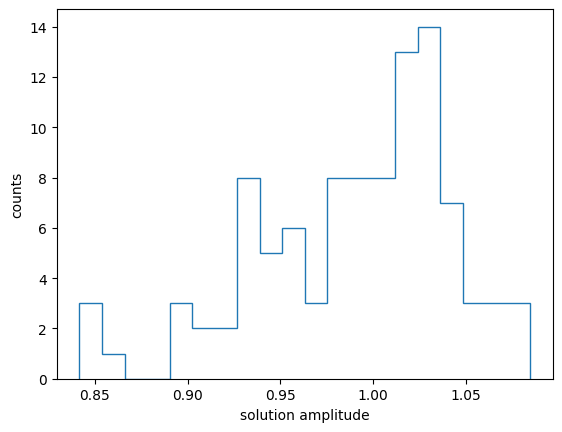

In [1317]:
plt.figure()
res = np.array(outs).flatten()
plt.hist(res[res>0], bins=20, histtype="step")
plt.xlabel("solution amplitude")
plt.ylabel("counts")
plt.show()

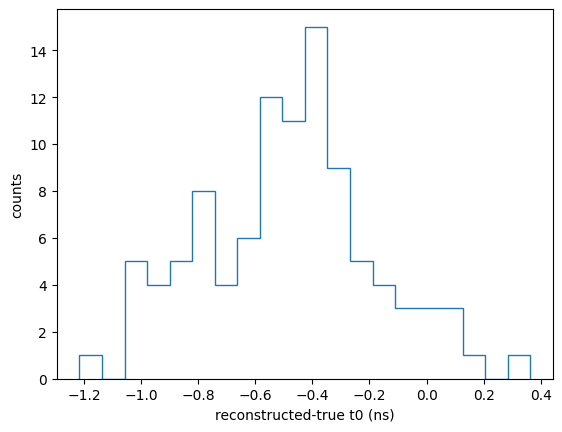

In [1318]:
plt.figure()
plt.hist([np.where(out>0)[0][0]-full_test_t0 for out,full_test_t0  in zip(outs, full_test_t0s)], bins=20, histtype="step")
plt.xlabel("reconstructed-true t0 (ns)")
plt.ylabel("counts")
plt.show()

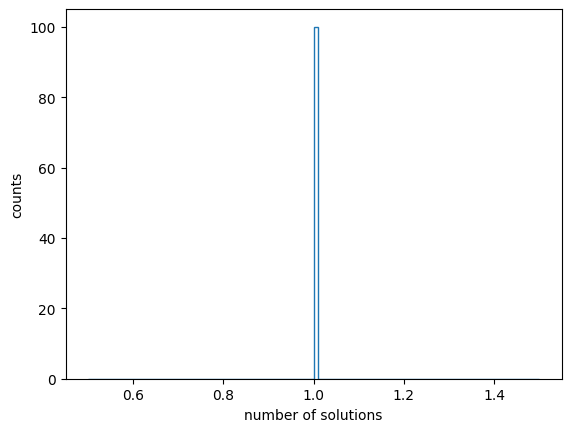

In [1319]:
plt.figure()
plt.hist([len(out[out>0]) for out in outs], bins=100, histtype="step")
plt.xlabel("number of solutions")
plt.ylabel("counts")
plt.show()

In [1320]:
%%time
outs_2pe = []
out = np.zeros(A.shape[1], dtype="float32")
ata = (A.T@A).astype("float32")
for i, w in enumerate(test_wfs_2pe):
    # Run NNLS
    optimize_nnls(A.astype("float32"), w.astype("float32"), ata, 
                  100, 1e-5, False, 0.4, 5,out)
    outs_2pe.append(out.copy())
    print(i, np.where(out>0)[0], out[out!=0])

0 [70] [1.9318578]
1 [63] [1.992786]
2 [60] [1.9443635]
3 [78 79] [1.2531729 0.6961093]
4 [78] [1.9797394]
5 [77] [2.1076005]
6 [77] [2.0131364]
7 [68] [2.0244894]
8 [72] [2.0140712]
9 [70] [2.0268176]
10 [56] [2.0225503]
11 [66] [2.0423214]
12 [57] [1.821381]
13 [57] [2.1668735]
14 [73] [2.0012066]
15 [75] [1.6970431]
16 [80] [1.754068]
17 [75] [1.9858768]
18 [74] [1.6703051]
19 [62] [2.1436906]
20 [60] [1.8582522]
21 [72] [1.7658437]
22 [70] [2.0555937]
23 [55] [1.9044138]
24 [75] [2.0818186]
25 [56] [2.040807]
26 [59] [1.9625045]
27 [75] [2.0106618]
28 [60] [1.8505486]
29 [79] [1.9202297]
30 [65] [2.0290515]
31 [66 67] [1.4167036  0.65576744]
32 [74 75] [1.0486842  0.85215425]
33 [70] [2.0039082]
34 [60] [1.9871695]
35 [71] [1.9864528]
36 [62] [2.0446043]
37 [62] [2.0354192]
38 [78] [2.0884328]
39 [77] [2.0063183]
40 [76] [1.8160309]
41 [62] [2.176972]
42 [63] [2.0006933]
43 [65] [2.0393937]
44 [68] [1.9894762]
45 [79] [1.8822984]
46 [54 58] [0.53618383 1.6048235 ]
47 [59] [1.934631

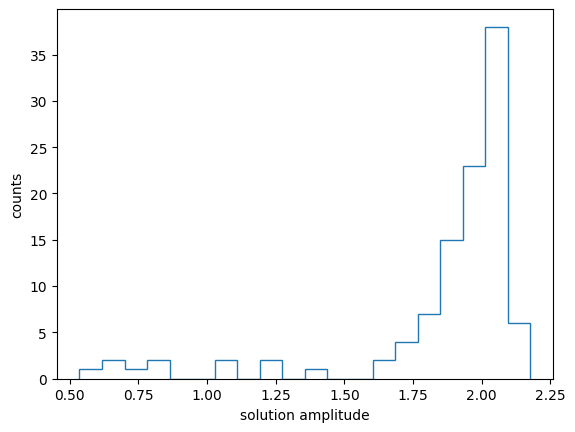

In [1321]:
plt.figure()
res = np.array(outs_2pe).flatten()
plt.hist(res[res>0], bins=20, histtype="step")
plt.xlabel("solution amplitude")
plt.ylabel("counts")
plt.show()

In [541]:
np.where(np.array([np.where(out>0)[0][0]-full_test_t0 for out,full_test_t0  in zip(outs, full_test_t0s)])<-3)[0]

array([ 4, 19, 35, 72, 75])

In [1135]:
optimize_nnls(A.astype("float32"), test_wfs_2pe[17].astype("float32"), ata, 
              100, 1e-5, False, min_value, 0, out)
out[out!=0]

array([0.12809578, 1.8806471 ], dtype=float32)

[0.9241083  0.09407172] [56 62]


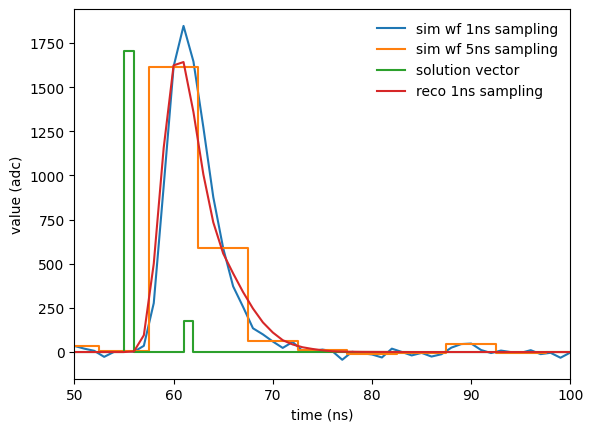

In [559]:
plt.figure()
i=0
out=np.zeros(A.shape[1], dtype="float32")
optimize_nnls(A.astype("float32"), test_wfs[i].astype("float32"), ata, 
              100, 1e-5, False, min_value, 5, 0,5,out)
#out[out<0.4] = 0
print(out[out>0], np.where(out)[0])
plt.plot( full_test_wfs[i], label="sim wf 1ns sampling")
plt.step(np.arange(0,wf_len)*upsample ,test_wfs[i], where="mid", label="sim wf 5ns sampling")
plt.step(np.arange(0,len(out)) , out*np.amax(full_test_wfs[i]) , label="solution vector")
plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(A_upsampled[:, out>0.5] * out[out>0.5])
#plt.plot(A_upsampled[:,72] * 1)

# plt.xlabel("sample")
# plt.ylabel("amplitude")
#plt.xlim([10*upsample,20*upsample])
plt.xlabel("time (ns)")
plt.ylabel("value (adc)")
plt.legend(frameon=False)
plt.xlim([50,100])
plt.show()

[0.56766796] [70] 73.1215390391294


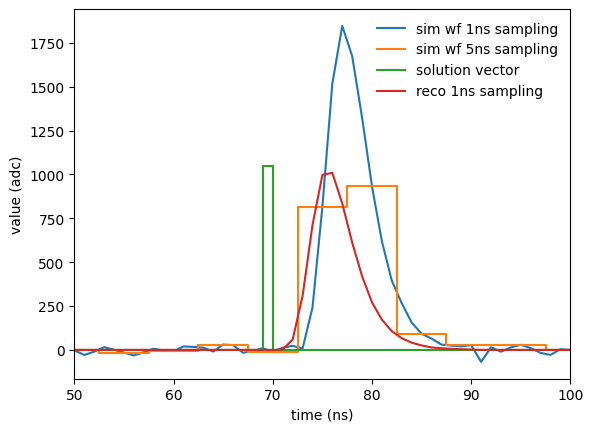

In [349]:
plt.figure()
i=4
optimize_nnls(A, test_wfs[i].astype("float32"), ata, 100, 10**-5, False, min_value, 15, out)
print(out[out>0], np.where(out)[0], full_test_t0s[i])
plt.plot( full_test_wfs[i], label="sim wf 1ns sampling")
plt.step(np.arange(0,wf_len)*upsample ,test_wfs[i], where="mid", label="sim wf 5ns sampling")
plt.step(np.arange(0,A.shape[1]) , out*np.amax(full_test_wfs[i]) , label="solution vector")
plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(A_upsampled[:, out>0.5] * out[out>0.5])
#plt.plot(A_upsampled[:,190] * 1)

# plt.xlabel("sample")
# plt.ylabel("amplitude")
plt.xlim([10*upsample,20*upsample])
plt.xlabel("time (ns)")
plt.ylabel("value (adc)")
plt.legend(frameon=False)
plt.show()

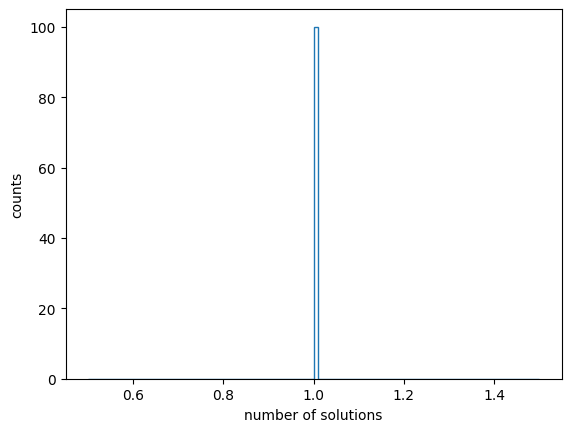

In [329]:
plt.figure()
plt.hist([len(out[out>0]) for out in outs], bins=100, histtype="step")
plt.xlabel("number of solutions")
plt.ylabel("counts")
plt.show()

In [139]:
%%time
outs = []
for i, w in enumerate(test_wfs):
    out = fit_waveform(w.astype("float32"))
    outs.append(out)
    print(i, np.where(out>0)[0], out[out>0])

0 [57] [1.1008236]
1 [65 67] [0.40012534 0.69251012]
2 [78] [1.32238144]
3 [77] [1.11422125]
4 [73 77] [0.82309195 0.40005022]
5 [72] [1.08129045]
6 [67] [1.10960169]
7 [62] [1.04801293]
8 [60] [0.84532372]
9 [72] [1.0130142]
10 [76 77] [0.66842449 0.4006741 ]
11 [62] [1.09797564]
12 [65 68] [0.70198285 0.40032399]
13 [70] [0.88586988]
14 [55 56] [0.40000869 0.40002965]
15 [57] [1.09384453]
16 [57] [1.02308324]
17 [56 59] [0.47817425 0.46285842]
18 [60] [1.05436723]
19 [60] [0.7953263]
20 [56] [0.9703708]
21 [75 79] [0.94468607 0.40000139]
22 [73] [1.31973721]
23 [65] [0.84010954]
24 [68] [1.13688738]
25 [57] [1.05627367]
26 [70] [0.81409111]
27 [60] [0.84973533]
28 [75] [1.03284626]
29 [60] [0.8577297]
30 [55 57] [0.42559081 0.65567154]
31 [58] [1.08708134]
32 [80 82] [0.68699608 0.40000075]
33 [60] [0.79556208]
34 [70] [0.79980244]
35 [76 80] [0.49052732 0.4002132 ]
36 [62] [1.06451177]
37 [58] [1.22401712]
38 [70 72] [0.40225213 0.63434603]
39 [75 79] [0.64895639 0.40007778]
40 [77]

In [522]:
%%time
outs = []
AA = A.T @ A
out = np.zeros(A.shape[1], dtype=A.dtype)
for i, w in enumerate(test_wfs):
    
    tntnn(A, w.astype("float32"), AA, 0, 0.2, 1.2, 0.3, 0,out)
        
    # optimize_nnls(A, w.astype("float32"), 100, 1e-5, 
    #           False, 0.5, 1, out)
    outs.append(out.copy())
    print(i, out[out>0])

0 [1.1626358]
1 [1.011868]
2 [0.99652654]
3 [1.2433053]
4 [0.5725425  0.46807292]
5 [1.2253665]
6 [0.97612226]
7 [0.99424547]
8 [0.8475603]
9 [1.0583456]
10 [1.2359432]
11 [1.0258528]
12 [0.34224987 0.72935957]
13 [0.8919796]
14 [1.008255]
15 [0.9791877]
16 [0.78768086]
17 [0.611828   0.34475228]
18 [1.162408]
19 [0.6929813]
20 [0.9678117]
21 [1.222129]
22 [1.2167816]
23 [0.8295669]
24 [0.6808457]
25 [1.0052886]
26 [0.30025378 0.7455045 ]
27 [0.8213791]
28 [1.0931501]
29 [0.82022]
30 [0.943346]
31 [0.31645346 0.7730642 ]
32 [0.4987877  0.52279985]
33 [0.74170643]
34 [0.35588062 0.5199167 ]
35 [0.6097922  0.45761257]
36 [1.0682532]
37 [1.0033854]
38 [1.0901529]
39 [0.80318594]
40 [1.0332788]
41 [0.8440755]
42 [0.78895724]
43 [1.0908239]
44 [0.66575927 0.5072713 ]
45 [0.6108855 0.320158 ]
46 [1.0075046]
47 [1.011772]
48 [0.35295346 0.5286701 ]
49 [0.9854244]
50 [1.1418358]
51 [1.046664]
52 [0.6996667]
53 [1.001509]
54 [1.0156441]
55 [1.1007042]
56 [0.74633634]
57 [0.7297707]
58 [1.034399

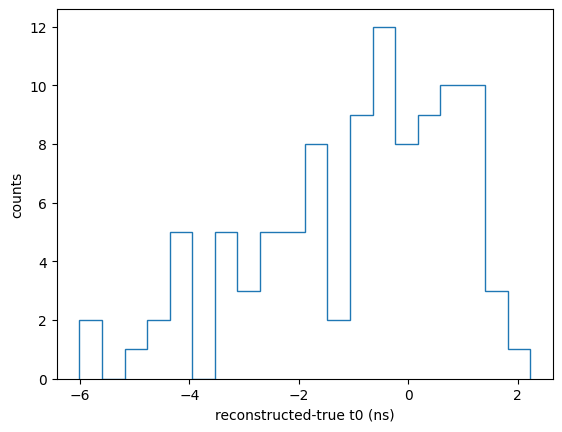

In [524]:
plt.figure()
plt.hist([np.where(out>0)[0][0]-full_test_t0 for out,full_test_t0  in zip(outs, full_test_t0s)], bins=20, histtype="step")
plt.xlabel("reconstructed-true t0 (ns)")
plt.ylabel("counts")
plt.show()

In [262]:


#m.hesse()

In [264]:
for i in np.where(np.array(m.values)>0.4)[0]:
    print(i, np.array(m.values)[i])

65 1.0122163368368047


In [111]:
full_test_t0s[17]

65.84521942453439

[1.05026854] [65]


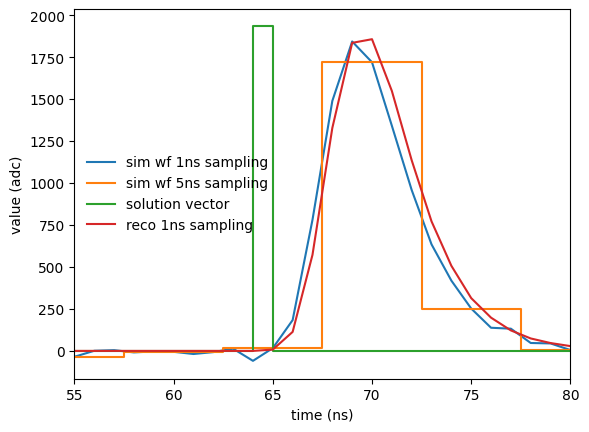

In [119]:
plt.figure()
i=0
out = np.array(m.values)
out[out<0.4] = 0
print(out[out>0], np.where(out)[0])
plt.plot( full_test_wfs[i], label="sim wf 1ns sampling")
plt.step(np.arange(0,wf_len)*upsample ,test_wfs[i], where="mid", label="sim wf 5ns sampling")
plt.step(np.arange(0,out_len) , out*np.amax(full_test_wfs[i]) , label="solution vector")
plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(A_upsampled[:, out>0.5] * out[out>0.5])
#plt.plot(A_upsampled[:,65] * 1)

# plt.xlabel("sample")
# plt.ylabel("amplitude")
#plt.xlim([10*upsample,20*upsample])
plt.xlabel("time (ns)")
plt.ylabel("value (adc)")
plt.legend(frameon=False)
plt.xlim([55,80])
plt.show()

In [30]:
A.shape

(32, 160)

In [32]:
out = np.zeros(out_len, dtype=A.dtype)
out.dtype

dtype('float32')

In [33]:
test_wfs[17].astype("float32") @ A

array([  230.83276,  4350.6753 , 11653.985  , ...,     0.     ,
           0.     ,     0.     ], dtype=float32)

In [34]:
A.T @ test_wfs[17].astype("float32")

array([  230.83276,  4350.6753 , 11653.985  , ...,     0.     ,
           0.     ,     0.     ], dtype=float32)

In [35]:
A.shape

(32, 160)

In [36]:
# Run NNLS
optimize_nnls(A, test_wfs[17].astype("float32"), 100, 1e-5, 
              False, 0.3, 1, out, )#True
out[out>0], np.where(out)

(array([0.9367788], dtype=float32), (array([76]),))

In [37]:
A.dtype

dtype('float32')

In [38]:
outs = []
for i, w in enumerate(test_wfs):
    out = np.zeros(out_len, dtype=A.dtype)
    optimize_nnls(A, w.astype("float32"), 100, 1e-5, 
              False, 0.5, 1, out)
    outs.append(out[out>0])
    print(i, out[out>0])

0 [0.93000954]
1 [1.0142552]
2 [0.99216753]
3 [0.9249953]
4 [1.0445487]
5 [0.8872328]
6 [0.9780067]
7 [1.0136545]
8 [0.9113654]
9 [0.99178517]
10 [1.0201755]
11 [0.90991235]
12 [0.96643066]
13 [1.0192695]
14 [0.9204475]
15 [1.0229211]
16 [0.9290737]
17 [0.9367788]
18 [1.0350131]
19 [0.85949147]
20 [1.0413536]
21 [1.000166]
22 [0.8974326]
23 [0.9564793]
24 [0.877649]
25 [1.0478958]
26 [0.90513843]
27 [0.997721]
28 [0.96135795]
29 [1.0010489]
30 [0.9902323]
31 [0.936067]
32 [1.0086615]
33 [0.88193786]
34 [1.0104952]
35 [1.0349416]
36 [1.0242827]
37 [0.9685202]
38 [1.0356541]
39 [1.0068483]
40 [1.0144792]
41 [0.98596066]
42 [0.9661543]
43 [0.9564443]
44 [1.0530003]
45 [0.9366515]
46 [0.9797508]
47 [0.9377334]
48 [0.9849059]
49 [0.98712194]
50 [0.93165636]
51 [0.9242445]
52 [1.0051076]
53 [1.0012742]
54 [0.93981767]
55 [1.0025603]
56 [1.031781]
57 [0.89617383]
58 [1.0586149]
59 [0.9201775]
60 [0.9906961]
61 [1.038765]
62 [1.0256224]
63 [0.96808404]
64 [0.97017354]
65 [0.9530882]
66 [1.0242

[0.93000954] [60]


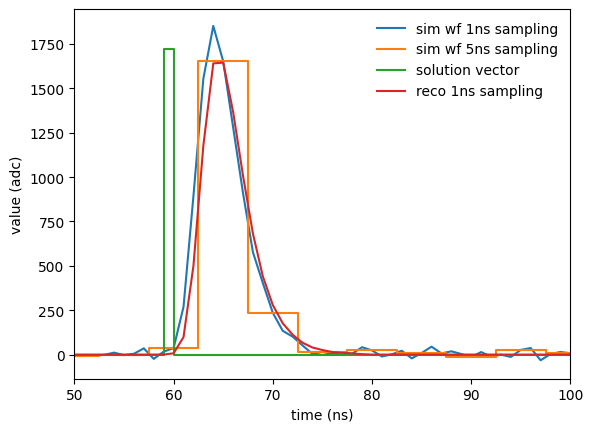

In [39]:
plt.figure()
i=0
optimize_nnls(A, test_wfs[i].astype("float32"), 100, 10**-5, False, 0.3, 10, out)
print(out[out>0], np.where(out)[0])
plt.plot( full_test_wfs[i], label="sim wf 1ns sampling")
plt.step(np.arange(0,wf_len)*upsample ,test_wfs[i], where="mid", label="sim wf 5ns sampling")
plt.step(np.arange(0,out_len) , out*np.amax(full_test_wfs[i]) , label="solution vector")
plt.plot(np.dot(A_upsampled, out), label="reco 1ns sampling")
#plt.plot(A_upsampled[:, out>0.5] * out[out>0.5])
#plt.plot(A_upsampled[:,190] * 1)

# plt.xlabel("sample")
# plt.ylabel("amplitude")
plt.xlim([10*upsample,20*upsample])
plt.xlabel("time (ns)")
plt.ylabel("value (adc)")
plt.legend(frameon=False)
plt.show()

In [40]:
# Run NNLS
optimize_nnls(A, test_wfs[3], 100, 1e-5, 
              False, 0.5, 0, out, False)

TypeError: optimize_nnls() takes from 8 to 8 positional arguments but 9 were given

In [ ]:
print(out[out>0])

In [ ]:
outs = []
for w in test_wfs:
    out = np.zeros(out_len)
    optimize_nnls(A, w, 100, 1e-5, 
              False, 0.3, 10, out)
    outs.append(out[out>0])
    #print(out[out>0])

In [ ]:
outs

In [ ]:
np.where(np.array([out[0] for out in outs]) <0.9)[0]

In [ ]:
plt.figure()
plt.hist([out[0] for out in outs], bins=100,histtype='step')
plt.show()

In [ ]:
out = np.zeros(out_len)

In [ ]:
np.where(out>0)[0], out[out>0]

In [ ]:
plt.figure()
i=17
optimize_nnls(A, test_wfs[i], 100, 10**-5, False, 0.2, 20, out, True)
print(np.where(out>0.1)[0], out[out>0.1])
plt.plot(full_test_wfs[i])
plt.step(np.arange(0,wf_len)*upsample ,test_wfs[i], where="mid")
plt.plot(np.dot(A_upsampled, out))
#plt.plot(A_upsampled[:, out>0.5] * out[out>0.5])
plt.plot(A_upsampled[:,78] * 1)

# plt.xlabel("sample")
# plt.ylabel("amplitude")
plt.xlim([10*upsample,20*upsample])
plt.show()

In [ ]:
out[out!=0]

In [ ]:
la.lapack.get_lapack_funcs(('potrf',), (np.full((10,10), 10, dtype="float32"),))

In [69]:
"""Python adaptations of some useful Matlab functions."""

from typing import Tuple
import numpy as np
from scipy.linalg.lapack import dlartg

@njit
def chol(a: np.ndarray, lower: bool = False) -> Tuple[np.ndarray, int]:
    """Cholesky factorization inspired by Matlab's chol function

    Uses LAPACK's POTRF subroutine to compute the factorization.

    Parameters
    ----------
    A : (M, M) ndarray
        Matrix to be decomposed
    lower : bool, optional
        Whether to compute the upper- or lower-triangular Cholesky
        factorization.  Default is upper-triangular.

    Returns
    -------
    c : (M, M) ndarray
        Upper- or lower-triangular Cholesky factor of a.
    info : int
        Status information on the POTRF call:
            * -i < 0 : the i-th argument had an illegal value.
            *    = 0 : successful execution.
            *  i > 0 : the leading minor of order i is not positive definite,
                         and the factorization could not be completed.
    """
    a1 = np.atleast_2d(np.asarray_chkfinite(a))

    # Dimension check
    if a1.ndim != 2:
        raise ValueError('Input array needs to be 2D but received '
                         f'a {a1.ndim}d-array.')
    # Squareness check
    if a1.shape[0] != a1.shape[1]:
        raise ValueError('Input array is expected to be square but has '
                         f'the shape: {a1.shape}.')

    # Quick return for square empty array
    if a1.size == 0:
        raise ValueError("Empty input array.")


    try:
        if lower:
            c = np.linalg.cholesky(a1)
        else:
            # For upper: A = U.T @ U, so U = cholesky(A).T
            c = np.linalg.cholesky(a1).T
        info = 0
    except:
        c = np.zeros_like(a1)
        info = 1  # Simplified error code
    
    return c, info



In [511]:
from typing import Tuple

import numpy as np
import scipy.linalg as la

@njit
def pcgnr(A: np.ndarray, b: np.ndarray,
          R: np.ndarray, lmbda=0) -> Tuple[np.ndarray, int]:
    """Left-Preconditioned CGNR.

    Solves the normal equations A^T A x = A^T b using a left-preconditioned
    conjugate gradient method. See Algorithm 9.7 from "Iterative Methods
    for Sparse Linear Systems" (2nd Ed.), by Yousef Saad.

    Parameters
    ----------
    A : (m, n) ndarray
        Left-hand side matrix
    b : (m,) ndarray
        Right-hand side vector
    R : (n, n) ndarray
        Left-preconditioner matrix

    Returns
    -------
    x : (n,) ndarray
        Solution of the normal equations system
    k : int
        Number of iterations
    """
    # need to modify this to add merges
    n = A.shape[1]
    x = np.zeros(n, dtype=A.dtype)
    r = b.copy()
    r_hat = A.T @ r - np.array([lmbda], dtype=r.dtype)
    #print(R.dtype, r_hat.dtype)
    y = np.linalg.solve(R, r_hat)
    z = np.linalg.solve(R, y)
    p = z.copy()

    gamma = np.dot(z, r_hat)
    prev_rr = -1

    for k in range(1, n+1):
        w = A @ p
        ww = np.dot(w,w)

        if ww == 0:
            break

        alpha = gamma/ww
        x_prev = x.copy()
        x += alpha*p
        r = b - A @ x
        r_hat = A.T @ r - - np.array([lmbda], dtype=r.dtype)

        # Enforce continuous improvement in the score.
        rr = np.dot(r_hat, r_hat)
        if 0 <= prev_rr <= rr:
            x = x_prev
            break
        prev_rr = rr

        y = np.linalg.solve(R, r_hat)
        z = np.linalg.solve(R, y)
        gamma_new = np.dot(z, r_hat)
        beta = gamma_new/gamma
        p = z + beta*p
        gamma = gamma_new

        if gamma == 0:
            break
            
    _ , x  = merge_in_sample(np.where(x!=0)[0], x, A, b, np.zeros(len(b),dtype=np.bool_)+1, np.zeros(len(x),dtype=np.bool_)+1)
    
    return x, k

In [512]:
@nb.njit
def dlartg(f, g):
    """
    Numba-compatible version of LAPACK dlartg
    Generate a plane rotation so that:
    [  c  s ] [ f ]   [ r ]
    [ -s  c ] [ g ] = [ 0 ]
    
    Returns: (c, s, r)
    where c = cos(theta), s = sin(theta), r = sqrt(f^2 + g^2)
    """
    if g == 0.0:
        c = 1.0
        s = 0.0
        r = abs(f)
    elif f == 0.0:
        c = 0.0
        s = 1.0 if g > 0 else -1.0
        r = abs(g)
    else:
        # Use the more stable algorithm
        if abs(f) > abs(g):
            t = g / f
            u = np.sqrt(1.0 + t * t)
            if f < 0:
                u = -u
            c = 1.0 / (u+10**-8)
            s = t * c
            r = f * u
        else:
            t = f / g
            u = np.sqrt(1.0 + t * t)
            if g < 0:
                u = -u
            s = 1.0 / (u+10**-8)
            c = t * s
            r = g * u
    
    return c, s, r

In [513]:
@njit
def _cholesky_delete(R: np.ndarray, BB: np.ndarray,
                    deletion_set: np.ndarray) -> np.ndarray:
    n = R.shape[1]
    num_deletions = len(deletion_set)

    speed_fudge_factor = 0.001
    if num_deletions > speed_fudge_factor * n:
        R, p = chol(BB)
        if p > 0:
            # This should never happen because we have already added
            # a sufficiently large "epsilon" to AA to do the
            # nonnegativity tests required to create the deleted_set.
            raise ValueError(
                "Could not compute Cholesky factorization"
            )
    else:
        for i in range(num_deletions):
            j = deletion_set[i]
            # This function is just a stripped version of Matlab's qrdelete.
            # http://pmtksupport.googlecode.com/svn/trunk/lars/larsen.m

            m, n = R.shape
            new_R = np.empty((m, n-1), dtype=R.dtype)
            
            # Copy columns before j
            new_R[:, :j] = R[:, :j]
            # Copy columns after j  
            new_R[:, j:] = R[:, j+1:]
            R = new_R

            for k in range(j, n):

                p = np.array([k, k+1])
                x = np.asarray_chkfinite(R[p, k])

                if x.shape != (2,):
                    raise ValueError(
                        "Input x must be a one-dimensional 2 element array")
            
                cs, sn, r = dlartg(x[0],x[1])
            
                G = np.array([[cs, sn], [-sn, cs]])
                r = np.array([r, 0])

                R[p, k] = r

                if k < n-1:  # adjust rest of row
                    R[p, k+1:] = G @ R[p, k+1:]

            R = R[:-1]#np.delete(R, -1)

    return R

In [514]:
"""
Non-negative Least Squares feasible solution.

Derived from Erich Frahm and Joseph Myre's Matlab implementation
available at https://github.com/ProfMyre/tnt-nn.
"""
@njit
def lsq_solve(A: np.ndarray, b: np.ndarray, AA: np.ndarray,
              epsilon: float, free_set: List[int], 
              deletions_per_loop: int, in_binding_set: List[int]=None, min_val=0, lmbda=0) -> LSQResult:
    """Computes a feasible solution non-negative least-squares problem.

    Uses an active-set strategy to handle the non-negativity constraints,
    combined with a preconditioned conjugate gradient solver for the
    unconstrained least-squares problem.
    """
    free_set = sorted(free_set, reverse=True)
    if in_binding_set is not None:
        binding_set = sorted(in_binding_set, reverse=True)
    else:
        binding_set = [0]
        binding_set.remove(0)

    # Reduce A to B.
    # B is a matrix that has all of the rows of A, but its
    # columns are a subset of the columns of A. The free_set
    # provides a map from the columns of B to the columns of A.
    B = A[:, np.array(free_set)].copy()

    # Reduce AA to BB.
    # BB is a symmetric matrix that has a subset of rows and
    # columns of AA. The free_set provides a map from the rows
    # and columns of BB to rows and columns of AA.
    free_set_arr = np.array(free_set)
    num_indices = free_set_arr.shape[0]

    BB = np.empty((num_indices, num_indices), dtype=AA.dtype)
    
    # Manually fill the BB array using nested loops
    # This directly implements the "cross-product" indexing logic
    for i in range(num_indices):
        row_idx = free_set_arr[i]
        for j in range(num_indices):
            col_idx = free_set_arr[j]
            BB[i, j] = AA[row_idx, col_idx]

    # Cholesky decomposition
    n = AA.shape[0]
    R, p = chol(BB)
    while p > 0:
        # It may be necessary to add to the diagonal of B'B to avoid
        # taking the square root of a negative number when there are
        # rounding errors on a nearly singular matrix. That's still OK
        # because we just use the Cholesky factor as a preconditioner.
        epsilon = epsilon * 10

        AA = AA + (epsilon * np.eye(n))

        free_set_arr = np.array(free_set)
        num_indices = free_set_arr.shape[0]
        
        BB = np.empty((num_indices, num_indices), dtype=AA.dtype)
    
        # Manually fill the BB array using nested loops
        # This directly implements the "cross-product" indexing logic
        for i in range(num_indices):
            row_idx = free_set_arr[i]
            for j in range(num_indices):
                col_idx = free_set_arr[j]
                BB[i, j] = AA[row_idx, col_idx]

        R, p = chol(BB)

    # Loops until solution is feasible
    dels = 0
    loops = 0
    lsq_loops = 0
    del_hist = []

    while True:
        loops += 1

        # Use PCGNR to find the unconstrained optimum in the "free" variables.
        reduced_x, k = pcgnr(B, b, R.astype(b.dtype), lmbda=lmbda)

        lsq_loops = max(k, lsq_loops)

        # Get a list of variables that must be deleted
        deletion_set = [i for i,_ in enumerate(free_set) if reduced_x[i] <= min_val]

        # If the current solution is feasible then quit.
        if not deletion_set:
            break

        # Sort the possible deletions by their reduced_x values to
        # find the worst violators.
        x_score = reduced_x[np.array(deletion_set)]
        set_index = np.argsort(x_score)
        deletion_set = [deletion_set[i] for i in set_index]

        # Limit the number of deletions per loop
        if len(deletion_set) > deletions_per_loop:
            deletion_set = deletion_set[:deletions_per_loop]

        deletion_set = sorted(deletion_set, reverse=True)
        del_hist.extend(deletion_set)
        dels += len(deletion_set)

        # Move the variables from "free" to "binding".
        # bound_variables = free_set[deletion_set]
        bound_variables = [free_set[i] for i in deletion_set]
        if binding_set is not None:
            binding_set.extend(bound_variables)
        else:
            binding_set = bound_variables
        free_set = [j for j in free_set if j not in bound_variables]
        if len(free_set) == 0:
            break
        # Reduce A to B
        # B is a matrix that has all of the rows of A, but its
        # columns are a subset of the columns of A. The free_set
        # provides a map from the columns of B to the columns of A.
        B = A[:, np.array(free_set)].copy()

        # Reduce AA to BB.
        # BB is a symmetric matrix that has a subset of rows and
        # columns of AA. The free_set provides a map from the rows
        # and columns of BB to rows and columns of AA.
        free_set_arr = np.array(free_set)
        num_indices = free_set_arr.shape[0]
    
        BB = np.empty((num_indices, num_indices), dtype=AA.dtype)
        
        # Manually fill the BB array using nested loops
        # This directly implements the "cross-product" indexing logic
        for i in range(num_indices):
            row_idx = free_set_arr[i]
            for j in range(num_indices):
                col_idx = free_set_arr[j]
                BB[i, j] = AA[row_idx, col_idx]
        # Compute R, the Cholesky factor.
        R = _cholesky_delete(R, BB, np.array(deletion_set))

    # Unscramble the column indices to get the full (unreduced) x.
    n = A.shape[1]
    x = np.zeros(n, dtype=A.dtype)
    if len(free_set) != 0:
        x[np.array(free_set)] = reduced_x

    # Compute the full (unreduced) residual.
    residual = b - (A @ x)

    # Compute the norm of the residual.
    score = np.sqrt(np.dot(residual,residual))

    return (score, x, residual, free_set, binding_set, AA,
            epsilon, del_hist, dels, loops, lsq_loops)


In [515]:
from typing import Union, List
import math

import numpy as np
import scipy.linalg as la

@guvectorize(
    [
        "void(float32[:,::1], float32[::1], float32[:,::1], float32, float32, float32, float32, float32, float32[::1])",
        "void(float64[:,::1], float64[::1], float64[:,::1], float32, float32, float32, float32, float32, float64[::1])",
    ],
    "(m,n),(m),(n,n),(),(),(),(),(),(n)",
    forceobj=True,
    **nb_kwargs,
)
def tntnn(A: np.ndarray, 
          b: np.ndarray,
          AA: Union[np.ndarray, None],
          rel_tol: float,
          red_c: float,
          exp_c: float,
          min_val: float,
          lmbda:float, 
          x:np.ndarray,
    ):

    """
    Example values: rel_tol=0, red_c=0.2, exp_c = 1.2
    red_c : reduction constant, controls how quickly modifications to
            the active set are restricted to a single variable per iteration. Large values of rc are preferable
            for difficult problems with a high condition number where the gradient can be an unreliable
            prediction of quality. 
    exp_c : expansion constant, opposes rc by controlling how many variables
            are added to the active set per iteration. Allowing the active set to be modified by a large
            number of variables per iteration is preferable for less complex problems with a low condition
            number where the gradient provides a good prediction of variables requiring constraint
    """

    hist = []

    m, n = A.shape

    if A.dtype != AA.dtype:
        raise ValueError(
            "A and AA must have same dtype."
            )

    if b.shape != (m,):
        raise ValueError(
            "A must have the same number of rows as the dimension of b."
            )

    # AA is a symmetric and positive definite (probably) n x n matrix.
    # If A did not have full rank, then AA is positive semi-definite.
    # Also, if A is very ill-conditioned, then rounding errors can make
    # AA appear to be indefinite. Modify AA a little to make it more
    # positive definite.
    epsilon = 10 * np.spacing(1) * la.norm(AA,1)
    AA = AA + (epsilon * np.eye(n))

    # In this routine A will never be changed, but AA might be adjusted
    # with a larger "epsilon" if needed. Working copies called B and BB
    # will be used to perform the computations using the "free" set
    # of variables.

    # Initialize sets.
    free_set = list(range(n))
    binding_set = None

    # This sets up the unconstrained, core LS solver
    score,x[:],residual, free_set, binding_set, AA, epsilon, _, dels, lps,_ = lsq_solve(
        A, b, AA, epsilon, free_set, n, in_binding_set=binding_set, min_val=min_val, lmbda=lmbda)

    # Outer loop
    OuterLoop = 0
    TotalInnerLoops = 0
    insertions = n
    continue_outer_loop = True  # used to return from inner loop

    while continue_outer_loop:

        OuterLoop += 1

        # Save this solution
        best_score = score
        best_x = x.copy()
        best_free_set = free_set[:]
        best_binding_set = binding_set[:]
        best_insertions = insertions
        max_insertions = math.floor(exp_c * best_insertions)

        # Compute the gradient of the "Normal Equations"
        gradient = A.T @ residual

        # Check the gradient components
        insertion_set = [
            i
            for i, bi in enumerate(binding_set)
            if gradient[bi] > 0
        ]
        insertions = len(insertion_set)

        # Are we done ?
        if insertions == 0:
            # There were no changes that were feasible.
            # We are done.
            hist.append([0 for i in range(6)])
            break

        # Sort the possible insertions by their gradients to find the
        # most attractive variables to insert.
        grad_score_coordinates = [binding_set[i] for i in insertion_set]
        grad_score = gradient[grad_score_coordinates]
        set_index = np.argsort(grad_score)[::-1]  # use descending order
        insertion_set = [insertion_set[i] for i in set_index]

        # Inner loop
        InnerLoop = 0
        while True:

            InnerLoop += 1
            TotalInnerLoops += 1

            # Adjust the number of insertions.
            insertions = math.floor(red_c * insertions)
            if insertions == 0:
                insertions = 1
            insertions = min(insertions, max_insertions)
            insertion_set = insertion_set[:insertions]

            # Move variables from "binding" to "free"
            free_variables = [binding_set[i] for i in insertion_set]
            free_set += free_variables

            new_binding_set = []
            if binding_set is not None:
                for item in binding_set:
                    if item not in free_variables:
                        new_binding_set.append(item)
            binding_set = new_binding_set

            # Compute a feasible solution using the unconstrained
            # least-squares solver of your choice.
            score,x[:],residual, free_set, binding_set, AA, epsilon, _, dels, lps,_ = lsq_solve(A, b, AA, epsilon,
                                   free_set, insertions, in_binding_set=binding_set, min_val=min_val, lmbda=lmbda)

            # Check for new best solution
            if score < best_score * (1-rel_tol):
                break

            # Restore the best solution
            score = best_score
            x[:] = best_x.copy()
            free_set = best_free_set[:]
            binding_set = best_binding_set[:]
            max_insertions = math.floor(exp_c * best_insertions)

            # Are we done ?
            if insertions == 1:
                # The best feasible change did not improve the score.
                # We are done.
                continue_outer_loop = False
                break


In [125]:
A

array([[   3.624791,    0.      ,    0.      , ...,    0.      ,
           0.      ,    0.      ],
       [1777.3542  , 1757.0774  , 1251.0796  , ...,    0.      ,
           0.      ,    0.      ],
       [ 303.2056  ,  476.3818  ,  739.8013  , ...,    0.      ,
           0.      ,    0.      ],
       ...,
       [   0.      ,    0.      ,    0.      , ...,    0.      ,
           0.      ,    0.      ],
       [   0.      ,    0.      ,    0.      , ...,    0.      ,
           0.      ,    0.      ],
       [   0.      ,    0.      ,    0.      , ...,    0.      ,
           0.      ,    0.      ]], dtype=float32)

In [126]:
out = np.zeros(out_len, dtype=A.dtype)

In [127]:
tntnn(A, test_wfs[3].astype("float32"), A.T @ A, 0, 0.2, 1.2, 0.3, 0,out)

/Users/georgemarshall/mint-analysis/.venv/lib/python3.12/site-packages/numba/np/ufunc/gufunc.py:261: RuntimeWarning: divide by zero encountered in tntnn
  return self.ufunc(*args, **kwargs)
/Users/georgemarshall/mint-analysis/.venv/lib/python3.12/site-packages/numba/np/ufunc/gufunc.py:261: RuntimeWarning: overflow encountered in tntnn
  return self.ufunc(*args, **kwargs)
/Users/georgemarshall/mint-analysis/.venv/lib/python3.12/site-packages/numba/np/ufunc/gufunc.py:261: RuntimeWarning: invalid value encountered in tntnn
  return self.ufunc(*args, **kwargs)


()

In [128]:
out[out>0]

array([1.0232409], dtype=float32)

In [433]:
outs = []
AA = A.T @ A
for i, w in enumerate(test_wfs):
    out = np.zeros(out_len, dtype=A.dtype)
    tntnn(A, w.astype("float32"), AA, 0, 0.2, 1.2, 0.3, 0,out)
        
    # optimize_nnls(A, w.astype("float32"), 100, 1e-5, 
    #           False, 0.5, 1, out)
    outs.append(out[out>0])
    print(i, out[out>0])

0 [1.0076579]
1 [0.97467124]
2 [1.044669]
3 [0.98881483]
4 [1.0271347]
5 [0.9345901]
6 [0.9607371]
7 [0.9504085]
8 [0.8241022]
9 [0.9019638]
10 [0.7602265]
11 [1.2068225]
12 [0.8049211]
13 [1.0151124]
14 [0.81832683]
15 [0.87702096]
16 [0.7951589]
17 [1.0688946]
18 [0.9382404]
19 [0.80844927]
20 [1.015301]
21 [0.77373064]
22 [1.1395444]
23 [1.0105513]
24 [1.0216112]
25 [1.040693]
26 [0.9424612]
27 [1.0159025]
28 [0.99570316]
29 [1.0254239]
30 [1.0518981]
31 [1.0045332]
32 [1.0189258]
33 [1.0164918]
34 [0.77616656]
35 [0.3924477 0.6565051]
36 [0.98053724]
37 [0.7105339]
38 [0.99919325]
39 [0.7904018]
40 [0.9214204]
41 [1.0149993]
42 [0.8060643]
43 [0.98821837]
44 [0.38239366 0.5026673 ]
45 [1.0270975]
46 [0.66645026]
47 [0.9269617]
48 [0.99512607]
49 [0.9254371]
50 [0.7139575]
51 [0.87181604]
52 [0.67107713]
53 [0.9436032]
54 [0.8109663]
55 [0.84381104]
56 [1.0295483]
57 [0.76187426]
58 [1.0047971]
59 [1.0333439]
60 [1.0280261]
61 [0.8661615]
62 [0.53295994 0.60445434]
63 [0.66753334 0.

In [426]:
out[out>0]

array([0.98881483], dtype=float32)

In [293]:
help(np.ix_)

Help on _ArrayFunctionDispatcher in module numpy:

ix_(*args)
    Construct an open mesh from multiple sequences.
    
    This function takes N 1-D sequences and returns N outputs with N
    dimensions each, such that the shape is 1 in all but one dimension
    and the dimension with the non-unit shape value cycles through all
    N dimensions.
    
    Using `ix_` one can quickly construct index arrays that will index
    the cross product. ``a[np.ix_([1,3],[2,5])]`` returns the array
    ``[[a[1,2] a[1,5]], [a[3,2] a[3,5]]]``.
    
    Parameters
    ----------
    args : 1-D sequences
        Each sequence should be of integer or boolean type.
        Boolean sequences will be interpreted as boolean masks for the
        corresponding dimension (equivalent to passing in
        ``np.nonzero(boolean_sequence)``).
    
    Returns
    -------
    out : tuple of ndarrays
        N arrays with N dimensions each, with N the number of input
        sequences. Together these arrays form a

In [295]:
np.ix_(, [1,2,3])

(array([[1],
        [2],
        [3]]),
 array([[1, 2, 3]]))

In [297]:
test = [1,2,3]

In [299]:
np.array([[p] for p in test]) , np.array([test])

(array([[1],
        [2],
        [3]]),
 array([[1, 2, 3]]))

In [910]:
plt.figure()
i=0
optimize_nnls(A, test_wfs[i], 2000, 10**-5, False, 0.5, out)
plt.plot(full_test_wfs[i])
plt.step(np.arange(0,wf_len)*upsample ,test_wfs[i], where="mid")
plt.plot(np.dot(A_upsampled, res))
#plt.plot(A_upsampled[:, out>0.5] * out[out>0.5])
#plt.plot(A_upsampled[:,190] * 1)

# plt.xlabel("sample")
# plt.ylabel("amplitude")
plt.xlim([10*upsample,20*upsample])
plt.show()

TypeError: optimize_nnls() missing 1 required positional argument: 'x'

<Figure size 640x480 with 0 Axes>

In [605]:
from __future__ import annotations

import numpy as np
from lgdo import lh5
from numba import guvectorize

from dspeed.errors import DSPFatal
from dspeed.utils import numba_defaults_kwargs as nb_kwargs


def wiener_filter(superpulse, noise_wf) -> np.ndarray:
    """Apply a Wiener filter to the waveform.

    Note
    ----
    The convolution is performed in the frequency domain.  This processor is
    composed of a factory function that is called using the `init_args`
    argument. The input and output waveforms are passed using `args`. The input
    must be the Fourier transform of the waveform. The output is the filtered
    waveform in the frequency domain.

    Parameters
    ----------
    file_name_array
        Array with path to an HDF5 file containing the time domain version of
        the superpulse in one column and noise waveform in another, the
        superpulse HDF5 group must be titled ``spms/processed/superpulse`` and
        the noise waveform must be called ``spms/processed/noise_wf``.

    JSON Configuration Example
    --------------------------

    .. code-block :: json

        "wf_wiener": {
            "function": "wiener_filter",
            "module": "dspeed.processors",
            "args": ["wf_bl_fft", "wf_wiener(2000,f)"],
            "unit": "dB",
            "init_args": ["/path/to/file/wiener.lh5"]
        }
    """

    # Read in the data

    # Now check that the data are valid

    if len(superpulse) < len(noise_wf):
        superpulse_tmp = np.zeros(len(noise_wf))
        superpulse_tmp[:len(superpulse)] = superpulse
        superpulse = superpulse_tmp

    if len(superpulse) <= 0:
        raise DSPFatal("The length of the filter must be positive")

    if len(superpulse) != len(noise_wf):
        raise DSPFatal(
            "The length of the superpulse must be equal to the length of the noise waveform"
        )

    if np.argmax(superpulse) <= 0 or np.argmax(superpulse) > len(superpulse):
        raise DSPFatal(
            "The index of the maximum of the superpulse must occur within the waveform"
        )

    # Transform these to the frequency domain to eventually create the wiener filter

    fft_superpulse = np.fft.fft(superpulse)
    fft_noise_wf = np.fft.fft(noise_wf)

    # Create the point spread function for the detector's response

    def psf(superpulse, fft_superpulse):
        delta = np.zeros_like(superpulse)
        arg_max = np.argmax(superpulse)
        delta[arg_max] = np.amax(superpulse)

        return fft_superpulse / np.fft.fft(delta)

    # Now create the wiener filter in the frequency domain

    fft_psf = psf(superpulse, fft_superpulse)
    psd_noise_wf = fft_noise_wf * np.conj(fft_noise_wf)
    psd_superpulse = fft_superpulse * np.conj(fft_superpulse)

    w_filter = (np.conj(fft_psf)) / (
        (fft_psf * np.conj(fft_psf)) + (psd_noise_wf / psd_superpulse)
    )

    # Create a factory function that performs the convolution with the wiener filter, the output is still in the frequency domain

    # @guvectorize(
    #     ["void(complex64[:], complex64[:])", "void(complex128[:], complex128[:])"],
    #     "(n)->(n)",
    #     **nb_kwargs(
    #         cache=False,
    #         forceobj=True,
    #     ),
    # )
    def wiener_out(w_in: np.ndarray, w_out: np.ndarray) -> None:
        """
        Parameters
        ----------
        fft_w_in
            the Fourier transformed input waveform.
        fft_w_out
            the filtered waveform, in the frequency domain.
        """
        w_out[:] = np.nan
        fft_w_in = np.fft.fft(w_in)

        if np.isnan(fft_w_in).any():
            return

        if len(w_filter) != len(fft_w_in):
            raise DSPFatal("The filter is not the same length of the input waveform")

        w_out[:] = np.fft.ifft(fft_w_in * w_filter)

    return wiener_out

In [606]:
samples.shape

(1000, 480)

In [607]:
w = wiener_filter(wf_template, samples[0,:])

In [611]:
wi_out = np.zeros(len(full_test_wfs[i]))

In [612]:
w(full_test_wfs[i], wi_out)

/var/folders/ch/dytr8n99541626ftf95bnnq40000gn/T/ipykernel_2056/3134464139.py:118: ComplexWarning: Casting complex values to real discards the imaginary part
  w_out[:] = np.fft.ifft(fft_w_in * w_filter)


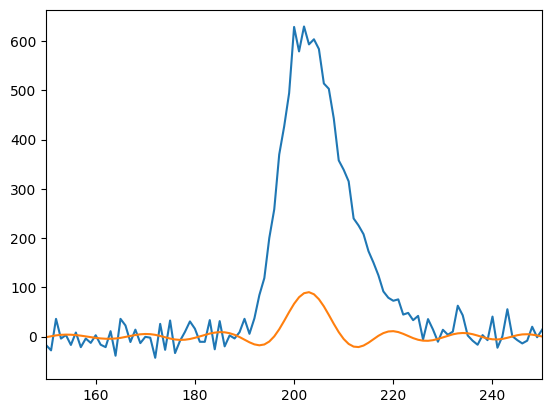

In [619]:
plt.figure()
plt.plot(full_test_wfs[i])
plt.plot(wi_out)
#plt.plot(np.dot(A_upsampled, wi_out))
plt.xlim(150, 250)
plt.show()

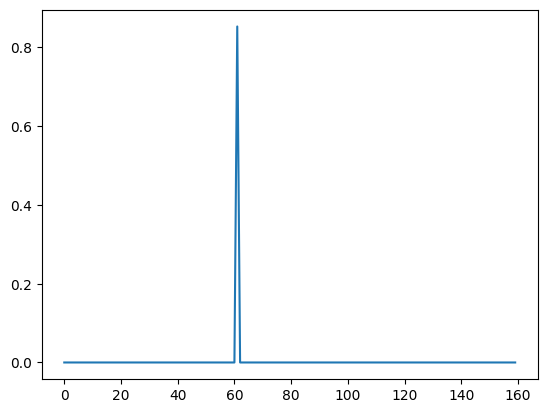

In [223]:
plt.figure()
plt.plot(out)
plt.show()

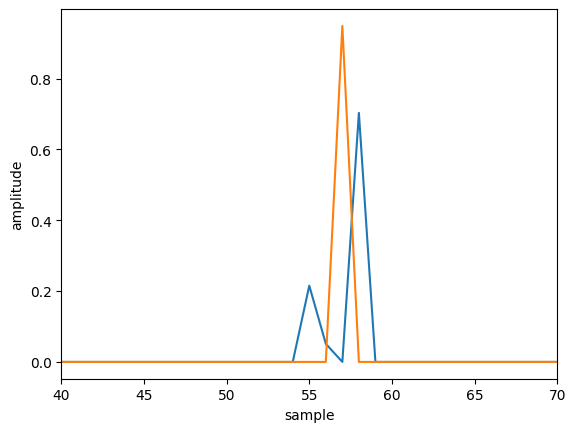

In [57]:
plt.figure()
wfn = 
nnls(A, test_wfs[0], 2000, 1e-6, False, 0,out)
plt.plot(out, label="nnls:0")
plt.plot(tb_out["wf_upsampled"]["values"].nda[0])
nnls(A, test_wfs[0], 2000, 1e-6, False, 0.5,out)
plt.plot(out, label="nnls:0.5")
plt.plot(tb_out["wf_upsampled"]["values"].nda[0])

plt.xlabel("sample")
plt.ylabel("amplitude")
plt.xlim([40,70])
plt.show()

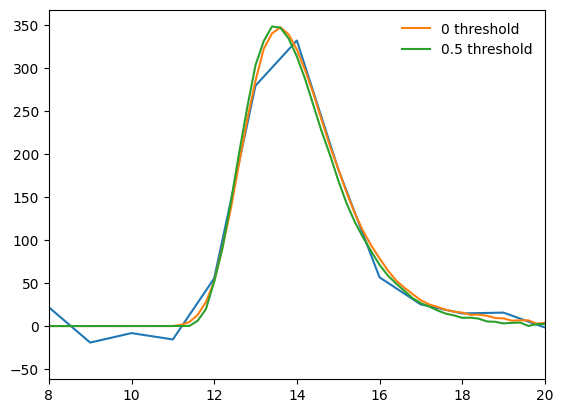

In [63]:
plt.figure()

plt.plot(test_wfs[0])
nnls(A, test_wfs[0], 2000, 1e-6, False, 0,out)
zres = np.zeros(out_len)
for i in range(out_len):
    zres += out[i] * A_upsampled[:,i]
plt.plot(np.arange(0,out_len,1)/upsample,zres, label="0 threshold")


nnls(A, test_wfs[0], 2000, 1e-6, False, 0.5,out)
zres = np.zeros(out_len)
for i in range(out_len):
    zres += out[i] * A_upsampled[:,i]
plt.plot(np.arange(0,out_len,1)/upsample, zres, label="0.5 threshold")

# plt.xlabel("sample")
# plt.ylabel("amplitude")
plt.xlim([8,20])
plt.legend(frameon=False)
plt.show()

In [ ]:
zres = np.zeros(out_len)
for i in range(out_len):
    zres += out[i] * A_upsampled[:,i]
t0_est = t0_trials[np.argmax(out)]


* could suppress all below some threshold e.g. 0.1/0.2?
* can define t0 here using the maximum.
    * how would this work with pileup?
* compare t0 to injected t0

In [31]:
zres = np.zeros(out_len)
for i in range(out_len):
    zres += out[i] * A_upsampled[:,i]
t0_est = t0_trials[np.argmax(out)]

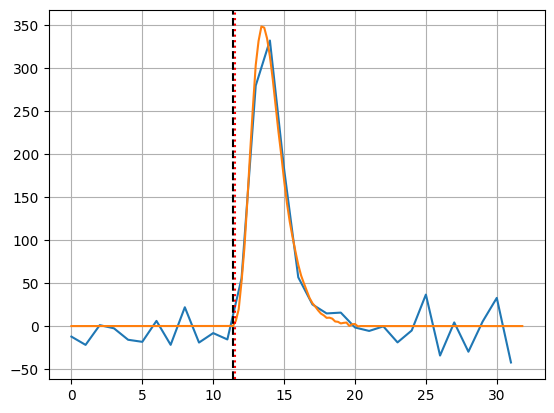

In [32]:
plt.figure()
plt.plot(test_wfs[0])
plt.plot(np.arange(0,out_len,1)/upsample, zres)
plt.axvline(t0_est, color="black", ls = "--")
plt.axvline(test_t0s[0], color="red", ls = ":")
plt.grid()
plt.show()

In [ ]:
plt.figure()
plt.plot(test_wfs[0])
plt.plot(np.arange(0,out_len,1)/upsample, zres)
plt.axvline(t0_est, color="black", ls = "--")
plt.axvline(test_t0s[0], color="red", ls = ":")
plt.grid()
plt.show()

In [33]:
b = WaveformTable(values=test_wfs,dt=5,dt_units="ns",t0=0,t0_units="ns")
    
# add everything into a lh5 structure and write it to disk
table = Table(size=len(b))
table.add_field("waveform",b,True)

In [34]:
table

Table(dict={'waveform': WaveformTable(dict={'t0': Array([0. 0. ... 0. 0.], attrs={'datatype': 'array<1>{real}', 'units': 'ns'}), 'dt': Array([5. 5. ... 5. 5.], attrs={'datatype': 'array<1>{real}', 'units': 'ns'}), 'values': ArrayOfEqualSizedArrays([[-12.23820549 -21.84968407 ... 32.71493064 -42.28479658] [ 5.13871787 -20.99414227 ... -13.81255093 -6.7165056 ] ... [ 5.84038103 -34.22230161 ... 16.13983362 -2.84417214] [ -5.5991369 17.10141678 ... 11.9750766 -7.85335267]], attrs={'datatype': 'array_of_equalsized_arrays<1,1>{real}'})}, attrs={'datatype': 'table{t0,dt,values}'})}, attrs={'datatype': 'table{waveform}'})

In [39]:
config = {
    "outputs": [
        "wf_blsub",
        "tp_max",
        "wf_max",
        "nnls_solution",
        "wf_upsampled",
        "t0"
    ],
    "processors":{
        "tp_min, tp_max, wf_min, wf_max": {
            "description": "find waveform max and min and the corresponding timepoints",
            "function": "min_max",
            "module": "dspeed.processors",
            "args": ["wf_blsub", "tp_min", "tp_max", "wf_min", "wf_max"],
            "unit": ["ns", "ns", "ADC", "ADC"]
        },
        "bl_mean , bl_std, bl_slope, bl_intercept": {
          "description": "finds mean and rms of waveform initial samples",
          "function": "linear_slope_fit",
          "module": "dspeed.processors",
          "args": [
            "waveform[0: 5]",
            "bl_mean",
            "bl_std",
            "bl_slope",
            "bl_intercept"
          ],
          "unit": ["ADC", "ADC", "ADC", "ADC"]
        },
       "wf_blsub": {
           "description": "subract baseline from waveform",
            "function": "subtract",
            "module": "numpy",
            "args": ["waveform", "bl_mean", "wf_blsub"],
            "unit": "ADC",
        },
        "nnls_solution": {
            "function": "optimize_nnls",
            "module": "dspeed.processors",
            "args": ["db.coefficient_matrix",
                "wf_blsub",
                "1000", "1e-6", "True", "db.min_value",
                "nnls_solution(db.solution_vector_length, period=db.solution_vector_resolution_in_ns*ns)"],
            "unit": "ADC/sample",
            "defaults":{"db.min_value":0}
        },
        "wf_upsampled": {
           "description": "get upsampled waveform",
            "function": "matmul",
            "module": "numpy",
            "args": [
                "nnls_solution", 
                "db.upsampled_matrix", 
                "wf_upsampled(db.solution_vector_length, period = db.solution_vector_resolution_in_ns*ns)"
            ],
            "unit": "ADC",
            "kwargs": { "signature": "(n),(n,n)->(n)", "types": ["dd->d"] },
        },
        "tp_min_up, tp_max_up, wf_min_up, wf_max_up": {
            "description": "find waveform max and min and the corresponding timepoints",
            "function": "min_max",
            "module": "dspeed.processors",
            "args": ["wf_upsampled", "tp_min_up", "tp_max_up", "wf_min_up", "wf_max_up"],
            "unit": ["ns", "ns", "ADC", "ADC"]
        },
        "t0": {
          "description": "walks backwards through asymmetric trap convolved waveform until below threshold which defines t0",
          "function": "time_point_thresh",
          "module": "dspeed.processors",
          "args": ["wf_upsampled", "5", "tp_max_up", 0, "t0"],
          "unit": "ns"
        }
        
    }
}



In [36]:
import yaml

In [34]:
!pwd

/Users/georgemarshall/mint-analysis/notebooks


In [35]:
with open("../configs/dsp/dsp_config.yaml", "w") as w:
    yaml.dump(config, w, sort_keys=False)

In [43]:
tb_out = run_one_dsp(
    table, 
    config,
    db_dict = {
        "coefficient_matrix":A,
        "upsampled_matrix":A_upsampled.T,
        "solution_vector_length": out_len, 
        "solution_vector_resolution_in_ns": 1, 
        "min_value":0,
    }
)

In [40]:
tb_out2 = run_one_dsp(
    table, 
    config,
    db_dict = {
        "coefficient_matrix":A,
        "upsampled_matrix":A_upsampled.T,
        "solution_vector_length": out_len, 
        "solution_vector_resolution_in_ns": 1, 
        "min_value":0.25,
    }
)

In [41]:
tb_out3 = run_one_dsp(
    table, 
    config,
    db_dict = {
        "coefficient_matrix":A,
        "upsampled_matrix":A_upsampled.T,
        "solution_vector_length": out_len, 
        "solution_vector_resolution_in_ns": 1, 
        "min_value":0.5,
    }
)

In [64]:
tb_out3["t0"]

Array([58. 73. 71. ... 65. 79. 64.], attrs={'datatype': 'array<1>{real}', 'units': 'ns'})

In [69]:
test_t0s*5

array([57.75559018, 72.11001737, 70.95313416, ..., 64.49947521,
       78.60079442, 62.62510187])

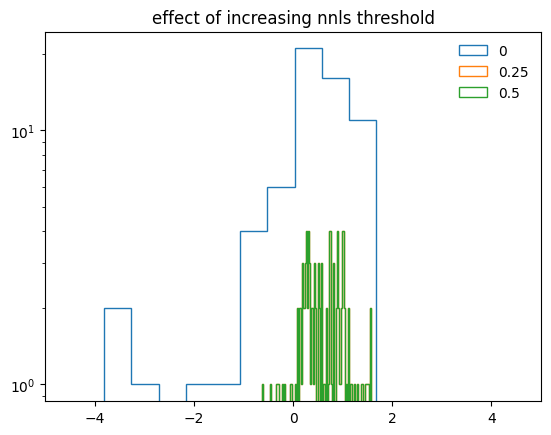

In [73]:
plt.figure()
plt.hist(
    tb_out["t0"]-test_t0s*5,
    bins=100,histtype="step", label=0
)
plt.hist(
    tb_out2["t0"]-test_t0s*5,
    bins=100,histtype="step", label=0.25
)
plt.hist(
    tb_out3["t0"]-test_t0s*5,
    bins=100,histtype="step", label=0.5
)
plt.yscale("log")
plt.legend(frameon=False)
plt.title("effect of increasing nnls threshold")
plt.xlim([-5,5])
plt.show()

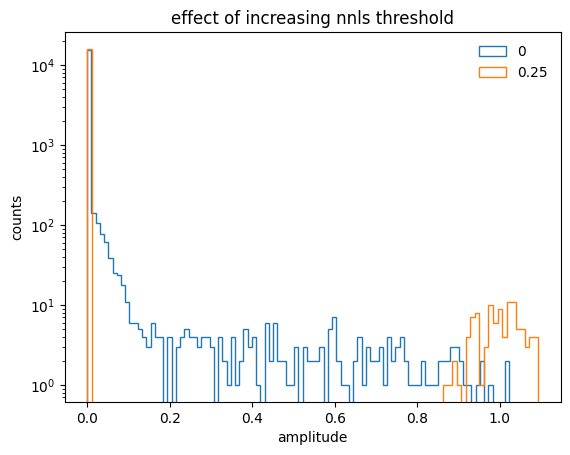

In [56]:
plt.figure()
plt.hist(
    tb_out["nnls_solution"]["values"].nda.flatten(),
    bins=100,histtype="step", label=0
)
plt.hist(
    tb_out2["nnls_solution"]["values"].nda.flatten(),
    bins=100,histtype="step", label=0.25
)
# plt.hist(
#     tb_out3["nnls_solution"]["values"].nda.flatten(),
#     bins=100,histtype="step", label=0.5
# )
plt.yscale("log")
plt.xlabel("amplitude")
plt.ylabel("counts")
plt.legend(frameon=False)
plt.title("effect of increasing nnls threshold")
plt.show()

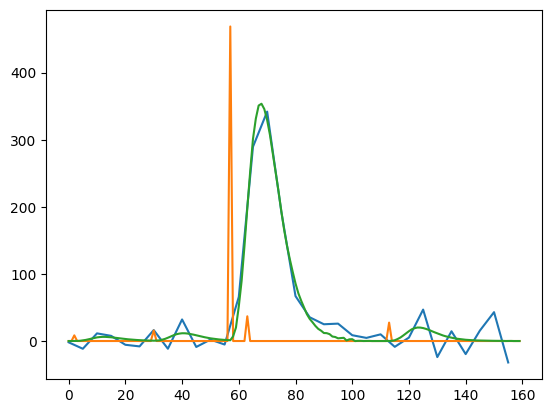

In [45]:
plt.figure()
plt.plot(np.arange(0,wf_len,1)*5, tb_out["wf_blsub"]["values"].nda[0])#/ np.nanmax(tb_out["wf_blsub"]["values"].nda[0])
plt.plot(tb_out["nnls_solution"]["values"].nda[0]*500)
plt.plot(tb_out["wf_upsampled"]["values"].nda[0])
plt.show()

In [46]:
tb_out["nnls_solution"]["values"]

ArrayOfEqualSizedArrays([[0.         0.         0.01690448 ... 0.
                          0.         0.        ]
                         [0.         0.         0.         ... 0.
                          0.         0.        ]
                         [0.         0.         0.         ... 0.
                          0.         0.        ]
                         ...
                         [0.         0.         0.         ... 0.
                          0.         0.        ]
                         [0.         0.         0.         ... 0.
                          0.         0.        ]
                         [0.         0.         0.         ... 0.
                          0.         0.        ]], attrs={'datatype': 'array_of_equalsized_arrays<1,1>{real}'})

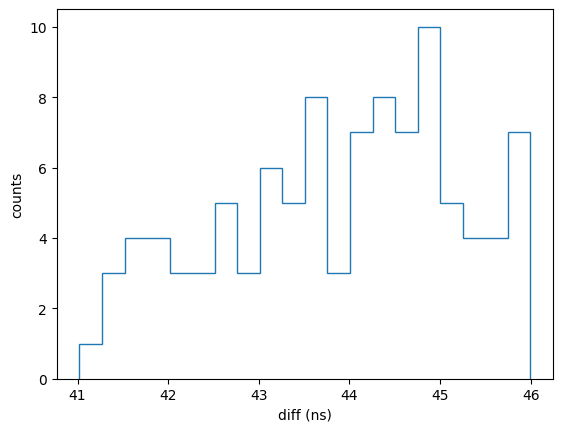

In [96]:
plt.figure()
plt.hist((tb_out["t0"].nda[0]-test_t0s), bins=20, histtype="step")
plt.xlabel("diff (ns)")
plt.ylabel("counts")
plt.show()

In [97]:
tb_out["t0"].nda[0]

57.0

In [8]:
def numba_ix(arr: np.array, rows: np.array, cols: np.array) -> np.array:
    """
    Numba compatible implementation of arr[np.ix_(rows, cols)] for 2D arrays.
    from https://github.com/numba/numba/issues/5894#issuecomment-974701551
    :param arr: 2D array to be indexed
    :param rows: Row indices
    :param cols: Column indices
    :return: 2D array with the given rows and columns of the input array
    """
    one_d_index = np.zeros(len(rows) * len(cols), dtype=np.int32)
    for i, r in enumerate(rows):
        start = i * len(cols)
        one_d_index[start : start + len(cols)] = cols + arr.shape[1] * r

    arr_1d = arr.reshape((arr.shape[0] * arr.shape[1], 1))
    slice_1d = np.take(arr_1d, one_d_index)
    return slice_1d.reshape((len(rows), len(cols)))

def is_singular(matrix):
    """
    Returns True if matrix det = 0 i.e. matrix is singular.
    """
    det = np.linalg.det(matrix)
    return abs(det) < np.finfo(np.float64).eps

In [ ]:
m, n = a.shape

ata = np.transpose(a) @ a
atb = b @ a  # Result is 1D - let NumPy figure it out

# Initialize vars
x[:] = np.zeros(n, dtype=np.float64)
s = np.zeros(n, dtype=np.float64)
# Inactive constraint switches
p = np.zeros(n, dtype=np.bool_)
pidx = np.arange(0, len(p), 1, dtype=np.int32)

# Projected residual
w = atb.copy().astype(np.float64)  # x=0. Skip (-ata @ x) term

# Overall iteration counter
# Outer loop is not counted, inner iter is counted across outer spins


In [ ]:

iter = 0
while (not p.all()) and (w[~p] > tol).any():
    # Get the "most" active coeff index and move to inactive set
    k = np.argmax(w * (~p))
    p[k] = True

    # Iteration solution
    s[:] = 0.0
    mat = numba_ix(ata, pidx[p], pidx[p])
    # check if matrix has full rank before solving
    if is_singular(mat) and allow_singularity:
        x[:] = np.nan
        return None

    s[p] = np.linalg.solve(mat, atb[p])

    # Inner loop
    while (iter < maxiter) and (s[p].min() <= 0):
        iter += 1
        inds = p * (s <= 0)
        alpha = (x[inds] / (x[inds] - s[inds])).min()
        x *= 1 - alpha
        x += alpha * s
        p[x <= tol] = False

        mat = numba_ix(ata, pidx[p], pidx[p])
        if is_singular(mat) and allow_singularity:
            x[:] = np.nan
            return None

        s[p] = np.linalg.solve(mat, atb[p])
        s[~p] = 0

    x[:] = s[:]
    w[:] = atb - ata @ x

    if iter == maxiter:
        return None

In [37]:
A

array([[1.11464806e-01, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.50558517e+02, 9.53024139e+01, 5.45017014e+01, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [3.66629395e+02, 3.48906006e+02, 3.19316467e+02, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       ...,
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00]], dtype=float32)

In [42]:
table.waveform.values.nda[0]

array([-12.23820549, -21.84968407,   1.09504749, ...,   5.16949258,
        32.71493064, -42.28479658])

In [90]:
b = table.waveform.values.nda[0]

In [91]:
a = A

In [92]:
m, n = a.shape

ata = np.transpose(a) @ a
atb = b @ a  # Result is 1D - let NumPy figure it out

# Initialize vars
x = np.zeros(n, dtype=np.float64)
s = np.zeros(n, dtype=np.float64)
# Inactive constraint switches
p = np.zeros(n, dtype=np.bool_)
pidx = np.arange(0, len(p), 1, dtype=np.int32)

# Projected residual
w = atb.copy().astype(np.float64)  # x=0. Skip (-ata @ x) term

In [93]:
A.shape, b.shape, ata.shape, atb.shape

((32, 160), (32,), (160, 160), (160,))

In [94]:
w[~p]

array([-6568.13842836, -6003.93914881, -5942.16952728, ...,
           0.        ,     0.        ,     0.        ])

In [95]:
# Get the "most" active coeff index and move to inactive set
k = np.argmax(w * (~p))
print(k)
p[k] = True

# Iteration solution
s[:] = 0.0
mat = numba_ix(ata, pidx[p], pidx[p])

s[p] = np.linalg.solve(mat, atb[p])

57


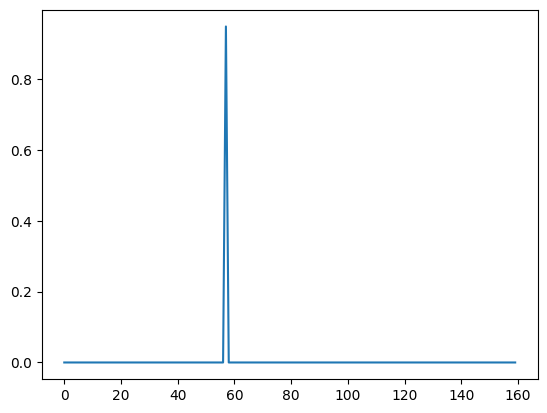

In [96]:
plt.figure()
plt.plot(s)
plt.show()

In [97]:
p

array([False, False, False, ..., False, False, False])

In [98]:
inds = p * (s <= 0)

In [99]:
p, (s <= 0)

(array([False, False, False, ..., False, False, False]),
 array([ True,  True,  True, ...,  True,  True,  True]))

In [100]:
alpha = (x[inds] / (x[inds] - s[inds])).min()

ValueError: zero-size array to reduction operation minimum which has no identity

In [101]:
alpha

0.0

In [102]:
s

array([0., 0., 0., ..., 0., 0., 0.])

In [103]:
tol = 1e-6

In [104]:
x *= 1 - alpha
x += alpha * s
p[x <= tol] = False

mat = numba_ix(ata, pidx[p], pidx[p])

s[p] = np.linalg.solve(mat, atb[p])
s[~p] = 0

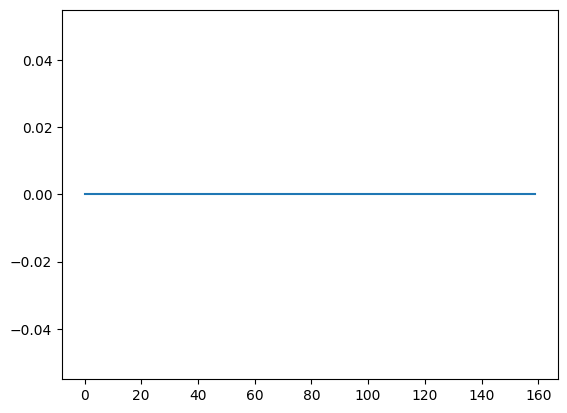

In [105]:
plt.figure()
plt.plot(s)
plt.show()

In [57]:
s

array([0., 0., 0., ..., 0., 0., 0.])

In [ ]:
# Get the "most" active coeff index and move to inactive set
k = np.argmax(w * (~p))
p[k] = True

# Iteration solution
s[:] = 0.0
mat = numba_ix(ata, pidx[p], pidx[p])
# check if matrix has full rank before solving
if is_singular(mat) and allow_singularity:
    x[:] = np.nan
    return None

s[p] = np.linalg.solve(mat, atb[p])

    # Inner loop
    while (iter < maxiter) and (s[p].min() <= 0):
        iter += 1
        inds = p * (s <= 0)
        alpha = (x[inds] / (x[inds] - s[inds])).min()
        x *= 1 - alpha
        x += alpha * s
        p[x <= tol] = False

        mat = numba_ix(ata, pidx[p], pidx[p])
        if is_singular(mat) and allow_singularity:
            x[:] = np.nan
            return None

        s[p] = np.linalg.solve(mat, atb[p])
        s[~p] = 0

    x[:] = s[:]
    w[:] = atb - ata @ x

    if iter == maxiter:
        return None

In [ ]:
from __future__ import annotations

import numpy as np
from numba import guvectorize

from ..errors import DSPFatal
from ..utils import numba_defaults_kwargs as nb_kwargs


@guvectorize(
    [
        "void(float32[:,::1], float32[::1], float32, float32, boolean, float32[::1])",
        "void(float64[:,::1], float64[::1], float64, float32, boolean, float64[::1])",
    ],
    "(m,n),(m),(),(),(),(n)",
    nopython=True,
    **nb_kwargs,
)
def optimize_nnls(
    a: np.ndarray,
    b: np.ndarray,
    maxiter: int,
    tol: float,
    allow_singularity: bool,
    x: np.ndarray,
) -> None:
    """Solve ``argmin_x || ax - b ||_2`` for ``x>=0``.
    Based on :func:`scipy.optimize.nnls` implementation. Which in turn is based on
    the algorithm in Bro, R. and De Jong, S. (1997), A fast non-negativity-constrained least squares algorithm. J. Chemometrics, 11: 393-401

    Parameters
    ----------
    a : (m, n) ndarray
        Coefficient matrix
    b : (m,) ndarray, float
        Right-hand side vector.
    maxiter: int
        Maximum number of iterations.
    tol: float
        Tolerance value used in the algorithm to assess closeness to zero in
        the projected residual ``(a.T @ (a x - b)`` entries. Increasing this
        value relaxes the solution constraints.
    allow_singularity: bool
        If matrix is not solvable (e.g. because of non full rank caused by
        float precision), no error is raised but all elements of the
        solution vector are set NaN
    x : ndarray
        Solution vector.

    JSON Configuration Example
    --------------------------

    .. code-block :: json

        "nnls_solution": {
            "function": "optimize_nnls",
            "module": "dspeed.processors",
            "args": ["db.coefficient_matrix",
                "wf_blsub",
                "1000", "1e-6", "True"
                "nnls_solution"],
        }
    """

    

    m, n = a.shape

    if n != len(x):
        raise DSPFatal(
            "n dimension of coefficient axis doesn't match solution vector length."
        )
    if m != len(b):
        raise DSPFatal(
            "m dimension of coefficient axis doesn't match right-hand vector length."
        )

    ata = np.transpose(a) @ a
    atb = b @ a  # Result is 1D - let NumPy figure it out

    # Initialize vars
    x[:] = np.zeros(n, dtype=np.float64)
    s = np.zeros(n, dtype=np.float64)
    # Inactive constraint switches
    p = np.zeros(n, dtype=np.bool_)
    pidx = np.arange(0, len(p), 1, dtype=np.int32)

    # Projected residual
    w = atb.copy().astype(np.float64)  # x=0. Skip (-ata @ x) term

    # Overall iteration counter
    # Outer loop is not counted, inner iter is counted across outer spins
    iter = 0
    while (not p.all()) and (w[~p] > tol).any():
        # Get the "most" active coeff index and move to inactive set
        k = np.argmax(w * (~p))
        p[k] = True

        # Iteration solution
        s[:] = 0.0
        mat = numba_ix(ata, pidx[p], pidx[p])

        # check if matrix has full rank before solving
        if is_singular(mat) and allow_singularity:
            x[:] = np.nan
            return None

        s[p] = np.linalg.solve(mat, atb[p])

        # Inner loop
        while (iter < maxiter) and (s[p].min() <= 0):
            iter += 1
            inds = p * (s <= 0)
            alpha = (x[inds] / (x[inds] - s[inds])).min()
            x *= 1 - alpha
            x += alpha * s
            p[x <= tol] = False

            mat = numba_ix(ata, pidx[p], pidx[p])
            if is_singular(mat) and allow_singularity:
                x[:] = np.nan
                return None

            s[p] = np.linalg.solve(mat, atb[p])
            s[~p] = 0

        x[:] = s[:]
        w[:] = atb - ata @ x

        if iter == maxiter:
            return None